In [1]:
import networkx as nx
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh
from math import log, ceil
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime import Session, EstimatorV2 as Estimator
from scipy.optimize import minimize
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RXGate, RZZGate
from collections import defaultdict
import random
from tqdm import tqdm
from collections import deque
import networkx as nx
from collections import deque
from qiskit import transpile
from qiskit.transpiler import PassManager, CouplingMap, Layout
from qiskit.transpiler.passes import (
    SetLayout,
    EnlargeWithAncilla,
    FullAncillaAllocation,
    ApplyLayout,
    SabreSwap,
    SabreLayout
)

def bounded_degree_bfs_tree(G, root, max_degree=3):
    """
    Constructs a BFS tree with bounded out-degree using dummy nodes.

    Parameters:
        G : networkx.Graph
            Input undirected graph.
        root : int
            Root node to start BFS.
        max_degree : int
            Maximum number of children a node can have in the tree.

    Returns:
        T : networkx.DiGraph
            Tree with dummy nodes added to enforce degree bounds.
    """
    T = nx.Graph()
    dummy_counter = 0
    visited = set([root])
    queue = deque([root])
    n = G.number_of_nodes()

    while queue:
        parent = queue.popleft()
        children = []

        for neighbor in G.neighbors(parent):
            if neighbor not in visited:
                visited.add(neighbor)
                children.append(neighbor)

        # Split children into groups of size at most `max_degree`
        if len(children) <= max_degree:
            for child in children:
                T.add_edge(parent, child)
                queue.append(child)
        else:
            # First group goes directly under the parent
            for child in children[:max_degree]:
                T.add_edge(parent, child)
                queue.append(child)

            # Remaining go under dummy nodes
            remaining = children[max_degree:]
            first_dummy=True
            while remaining:
                dummy = n + dummy_counter
                dummy_counter += 1
                if first_dummy:
                    T.add_edge(parent, dummy)
                else:
                    T.add_edge(dummy-1, dummy)

                for i in range(min(max_degree, len(remaining))):
                    child = remaining.pop(0)
                    T.add_edge(dummy, child)
                    queue.append(child)             
                first_dummy=False

    return T

def dfs_spanning_tree(G, root=0):
    """
    Constructs a DFS spanning tree of G rooted at `root`.

    Parameters:
        G : networkx.Graph
            Input undirected graph.
        root : int
            Root node to start DFS.

    Returns:
        T : networkx.DiGraph
            DFS tree (no dummy nodes, no degree bounds).
    """
    T = nx.Graph()
    visited = set()

    def dfs(current):
        visited.add(current)
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                T.add_edge(current, neighbor)
                dfs(neighbor)

    dfs(root)
    return T

def build_tree_cluster(G, source, n):
    """
    Grow a connected cluster (tree) from `source` by BFS until it has `n` nodes.
    Returns the set of nodes in the cluster and the tree edges.
    """
    visited = set([source])
    tree_edges = []
    queue = deque([source])

    while len(visited) < n and queue:
        current = queue.popleft()
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                tree_edges.append((current, neighbor))
                queue.append(neighbor)
                if len(visited) == n:
                    break

    return G.subgraph(visited)

def get_coupling_graph(backend):
    edges = backend.configuration().coupling_map
    G = nx.Graph()
    G.add_edges_from(edges)
    return G

def find_linear_chain(backend, target_length):
    coupling_map = backend.coupling_map

    # adjacency as a dict: {qubit: [connected_qubits]}
    adj = {i: [] for i in range(backend.configuration().num_qubits)}
    for (i, j) in coupling_map:
        adj[i].append(j)
        adj[j].append(i)

    def dfs(node, visited, path):
        if len(path) == target_length:
            return path
        for neighbor in adj[node]:
            if neighbor not in visited:
                result = dfs(neighbor, visited | {neighbor}, path + [neighbor])
                if result:
                    return result
        return None

    for start in adj:
        result = dfs(start, {start}, [start])
        if result:
            return result
    return None

def gradient_graph(graph : nx.Graph, tree=None, title=None):
    if not tree:
        tree = graph
    # adj_matrix = nx.adjacency_matrix(tree, nodelist=range(tree.number_of_nodes())).todense()
    adj_matrix = nx.adjacency_matrix(tree).todense()
    L = laplacian(adj_matrix)
    vals, vecs = eigh(L)
    fiedler = vecs[:,1]
    sorted = np.argsort(fiedler)

    fiedler_dict = {}
    n = len(graph.nodes())
    fiedler_dict = {sorted[i] : fiedler[sorted[i]] for i in range(n)}

    values = [fiedler_dict[node] for node in graph.nodes()]
    pos = nx.kamada_kawai_layout(graph)
    nx.draw(graph, pos, node_color=values, cmap=plt.cm.viridis, with_labels=True)
    # plt.colorbar(label="Fiedler Vector Value")
    if title:
        plt.title(title)
    plt.show()

def relabel_02n(G):
    # Create a mapping from old labels to new integer labels
    old_labels = list(G.nodes())
    mapping = {old_label: new_label for new_label, old_label in enumerate(old_labels)}
    
    # Relabel the graph
    G_relabelled = nx.relabel_nodes(G, mapping, copy=True)
    
    # Store the old labels as node attributes
    for new_label, old_label in mapping.items():
        G_relabelled.nodes[old_label]['old_label'] = new_label

    mapping = {new_label: old_label for new_label, old_label in enumerate(old_labels)}
    return G_relabelled, mapping  # Also return the mapping for reference

def graph_fiedler_sort(graph):
    adj_matrix = nx.adjacency_matrix(graph, nodelist=range(graph.number_of_nodes())).todense()
    L = laplacian(adj_matrix)
    vals, vecs = eigh(L)
    fiedler = vecs[:,1]
    sorted_nodes = np.argsort(fiedler)
    return sorted_nodes

def build_bfs_tree(G, source):
    """
    Build a BFS tree from a graph starting at the given source node.
    
    Parameters:
    - G: networkx.Graph or networkx.DiGraph
    - source: node in G from which BFS starts

    Returns:
    - T: networkx.DiGraph representing the BFS tree
    """
    bfs_edges = list(nx.bfs_edges(G, source))
    
    T = nx.Graph()  # BFS tree is rooted and directed
    T.add_nodes_from(G.nodes())
    T.add_edges_from(bfs_edges)

    return T

def wraparound_spanning_tree(G):
    # 1. Start from a low-degree node (likely on the periphery)
    start = min(G.degree, key=lambda x: x[1])[0]

    # 2. Perform BFS from start and get the last visited node (furthest)
    bfs_nodes = list(nx.bfs_tree(G, source=start))
    end = bfs_nodes[-1]

    # 3. Shortest path from start to end (serves as "backbone")
    backbone_path = nx.shortest_path(G, source=start, target=end)

    # 4. Initialize tree with backbone edges
    T = nx.Graph()
    T.add_nodes_from(G.nodes)
    for u, v in zip(backbone_path, backbone_path[1:]):
        T.add_edge(u, v)

    # 5. BFS from all nodes in backbone to grow the tree and keep it connected
    visited = set(backbone_path)
    queue = list(backbone_path)
    order = []

    while queue:
        current = queue.pop(0)
        if current not in order:
            order.append(current)
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                T.add_edge(current, neighbor)
                visited.add(neighbor)
                queue.append(neighbor)
                order.append(neighbor)
    return T, order

def initial_layout(graph : nx.Graph, backend, how='fiedler', topology='tree_dfs', root_on_backend=None):
    num_nodes = graph.number_of_nodes()
    sorted_nodes = graph_fiedler_sort(graph)

    if topology=='chain':
        chain = find_linear_chain(backend, num_nodes)
    else:
        G = get_coupling_graph(backend)

        if not root_on_backend:
            root_on_backend = backend.num_qubits//2
        tree_layout = build_tree_cluster(G, source=root_on_backend, n=num_nodes)
        degrees = tree_layout.degree()
    
        # Find the node with the minimum degree
        min_node = min(degrees, key=lambda x: x[1])[0]

        if topology=='tree_dfs':
            order = list(nx.dfs_preorder_nodes(tree_layout, source=root_on_backend))
        elif topology=='tree_wrap':
            tree, order = wraparound_spanning_tree(tree_layout)
            order = list(nx.dfs_preorder_nodes(tree, source=min_node))

    if how=='fiedler':
        if topology=='chain':
            logical_to_physical = {sorted_nodes[i]: chain[i] for i in range(num_nodes)}
        else:
            logical_to_physical = {sorted_nodes[i]: order[i] for i in range(num_nodes)}
    elif how=='trivial':
        logical_to_physical = {i: i for i in range(num_nodes)}
    elif how=='random':
        random_map = list(range(num_nodes))
        random.seed(0)
        random.shuffle(random_map)
        logical_to_physical = {i: random_map[i] for i in range(num_nodes)}
    else:
        print("Invalid starting layout!!!")
        return -1

    return logical_to_physical

def sabre_layout(circuit:QuantumCircuit, backend):
    circuit = transpile(circuit, basis_gates=backend.basis_gates, seed_transpiler=0)
    pm = PassManager()
    pm.append(SabreLayout(backend.coupling_map, skip_routing=True, seed=0))
    pm.run(circuit)

    layout = pm.property_set["layout"]
    mapping_dict = {i: layout[q] for i, q in enumerate(circuit.qubits)}
    return mapping_dict

def build_max_cut_paulis(graph: nx.Graph) -> list[tuple[str, float]]:
    """Convert NetworkX graph to Pauli list for MaxCut."""
    pauli_list = []
    num_nodes = len(graph.nodes())
    
    for edge in graph.edges(data=True):
        u, v, data = edge
        paulis = ["I"] * num_nodes
        
        # NetworkX nodes can be any hashable type, so we use positional indices
        paulis[u] = "Z"
        paulis[v] = "Z"
        
        # Get weight with default 1.0 if not specified
        weight = data.get('weight', 1.0)
        
        # Reverse string to match RustworkX qubit ordering convention
        pauli_list.append(("".join(paulis)[::-1], float(weight)))
    
    return pauli_list
def get_hamiltonian(graph):
    max_cut_paulis = build_max_cut_paulis(graph)
    cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)
    return cost_hamiltonian

def sabre_routed_circuit(circuit:QuantumCircuit, backend, reps=2, swap_heuristic='lookahead', opt_level=3):
    basis_gates=backend.basis_gates
    coupling_map = backend.coupling_map

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)

    pm = PassManager([
        # SetLayout(initial_layout),
        SabreLayout(coupling_map, skip_routing=True, seed=0),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic, seed=0)
    ])

    # Transpile using the custom pipeline
    transpiled = pm.run(basis_change)
    return transpiled

from qiskit.circuit.library import QAOAAnsatz
def gen_QAOA_circuit(graph:nx.Graph, reps=2):
    cost_hamiltonian = get_hamiltonian(graph)
    circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)
    circuit.measure_all()
    return circuit

from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

def custom_qaoa_ansatz(cost_graph: nx.Graph, layout: dict, coupling_map: list[tuple[int, int]], reps: int) -> QuantumCircuit:
    num_qubits = len(cost_graph.nodes)
    circuit = QuantumCircuit(num_qubits)

    # Parameters
    gammas = ParameterVector('γ', reps)
    betas = ParameterVector('β', reps)

    # Hadamard initialization
    circuit.h(range(num_qubits))

    # Coupling graph for distance calculation
    coupling_graph = nx.Graph()
    coupling_graph.add_edges_from(coupling_map)

    def physical_distance(q1, q2):
        try:
            return nx.shortest_path_length(coupling_graph, q1, q2)
        except nx.NetworkXNoPath:
            return float('inf')

    # Precompute sorted edges (by physical adjacency/distance)
    edge_info = []
    for i, j in cost_graph.edges():
        p_i = layout[i]
        p_j = layout[j]
        dist = physical_distance(p_i, p_j)
        edge_info.append((i, j, dist))
    edge_info.sort(key=lambda x: x[2])

    # Build QAOA layers
    for rep in range(reps):
        # Cost Layer
        for i, j, _ in edge_info:
            circuit.append(RZZGate(2*gammas[rep]), [i, j])
        # circuit.barrier()

        # Mixer Layer (RX(2*β))
        for q in range(num_qubits):
            circuit.rx(2 * betas[rep], q)
        # circuit.barrier()
    circuit.measure_all()

    return circuit

def custom_routed_circuit(circuit : QuantumCircuit, initial_mapping, backend, reps=2, swap_heuristic='lookahead', opt_level=3):
    basis_gates = backend.basis_gates
    coupling_map = backend.coupling_map

    mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})

    pm = PassManager([
        SetLayout(mapping_layout),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic, seed=0),
    ])

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)
    transpiled = pm.run(basis_change)

    return transpiled

def final_optimized_circuit(circuit, backend, initial_mapping=None, opt_level=3):
    if initial_mapping:
        mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})
        pm = generate_preset_pass_manager(optimization_level=opt_level, initial_layout=mapping_layout, backend=backend)
        candidate_circuit = pm.run(circuit)
    else:
        pm = generate_preset_pass_manager(optimization_level=opt_level, backend=backend)
        candidate_circuit = pm.run(circuit)
    return candidate_circuit


def QAOA_max_cut(candidate_circuit:QuantumCircuit, cost_hamiltonian:SparsePauliOp, backend, reps=2, estimator_shots=1000, sampler_shots=1000):
    initial_gamma = np.pi
    initial_beta = np.pi/2
    init_params = [initial_gamma, initial_beta] * reps

    objective_func_vals = [] # Global variable

    def cost_func_estimator(params, ansatz, hamiltonian, estimator:Estimator):
        isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

        pub = (ansatz, isa_hamiltonian, params)
        job = estimator.run([pub])

        results = job.result()[0]
        cost = results.data.evs

        objective_func_vals.append(cost)

        return cost

    with Session(backend=backend) as session:
        estimator = Estimator(mode=session)
        estimator.options.default_shots = estimator_shots

        estimator.options.dynamical_decoupling.enable = True
        estimator.options.dynamical_decoupling.sequence_type = "XY4"
        estimator.options.twirling.enable_gates = True
        estimator.options.twirling.num_randomizations = "auto"

        result = minimize(
            cost_func_estimator,
            init_params,
            args=(candidate_circuit, cost_hamiltonian, estimator),
            method="COBYLA",
            tol=1e-2,
        )
    optimized_circuit = candidate_circuit.assign_parameters(result.x)

    sampler = Sampler(mode=backend)
    sampler.options.default_shots = sampler_shots

    # Set simple error suppression/mitigation options
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.dynamical_decoupling.sequence_type = "XY4"
    sampler.options.twirling.enable_gates = True
    sampler.options.twirling.num_randomizations = "auto"

    pub= (optimized_circuit, )
    job = sampler.run([pub], shots=int(sampler_shots))
    counts_int = job.result()[0].data.meas.get_int_counts()
    counts_bin = job.result()[0].data.meas.get_counts()
    shots = sum(counts_bin.values())
    final_distribution_int = {key: val/shots for key, val in counts_int.items()}
    final_distribution_bin = {key: val/shots for key, val in counts_bin.items()}

    return final_distribution_bin
    # keys = list(final_distribution_bin.keys())
    # values = list(final_distribution_bin.values())
    # most_likely = keys[np.argmax(np.abs(values))]

    # return most_likely[::-1]

def optimized_parameters(candidate_circuit: QuantumCircuit, cost_hamiltonian:SparsePauliOp, backend, reps=2, shots=100):
    initial_gamma = np.pi
    initial_beta = np.pi/2
    init_params = [initial_gamma, initial_beta] * reps

    objective_func_vals = [] # Global variable

    def cost_func_estimator(params, ansatz, hamiltonian, estimator):
        isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

        pub = (ansatz, isa_hamiltonian, params)
        job = estimator.run([pub])

        results = job.result()[0]
        cost = results.data.evs

        objective_func_vals.append(cost)

        return cost

    with Session(backend=backend) as session:
        estimator = Estimator(mode=session)
        estimator.options.default_shots = shots

        estimator.options.dynamical_decoupling.enable = True
        estimator.options.dynamical_decoupling.sequence_type = "XY4"
        estimator.options.twirling.enable_gates = True
        estimator.options.twirling.num_randomizations = "auto"

        result = minimize(
            cost_func_estimator,
            init_params,
            args=(candidate_circuit, cost_hamiltonian, estimator),
            method="COBYLA",
            tol=1e-2,
        )
        return result.x
    
def sample_distribution(candidate_circuit:QuantumCircuit, optimized_params, backend, shots=1000):
    optimized_circuit = candidate_circuit.assign_parameters(optimized_params)

    sampler = Sampler(mode=backend)
    sampler.options.default_shots = shots

    # Set simple error suppression/mitigation options
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.dynamical_decoupling.sequence_type = "XY4"
    sampler.options.twirling.enable_gates = True
    sampler.options.twirling.num_randomizations = "auto"

    pub= (optimized_circuit, )
    job = sampler.run([pub], shots=int(1e4))
    counts_int = job.result()[0].data.meas.get_int_counts()
    counts_bin = job.result()[0].data.meas.get_counts()
    shots = sum(counts_bin.values())
    final_distribution_int = {key: val/shots for key, val in counts_int.items()}
    final_distribution_bin = {key: val/shots for key, val in counts_bin.items()}

    return final_distribution_bin

def evaluate_cut(graph: nx.Graph, bitstring: str) -> float:
    cut_value = 0.0
    for u, v in list(graph.edges()):
        if bitstring[u] != bitstring[v]:  # Nodes are in different partitions
            cut_value += 1
    return cut_value

def maxcut_dict(graph, cut_dict):
    mc_dict = defaultdict(int)
    for bitstr, prob in cut_dict.items():
        mc_dict[evaluate_cut(graph, bitstr[::-1])] += prob
    return mc_dict

import networkx as nx
import matplotlib.pyplot as plt
import math

def draw_graph_custom(G, node_labels=True, edge_labels=False, layout='kamada_kawai', node_size=100, font_size=6, highlight_nodes=None, title=None):
    """
    Draws a NetworkX graph with various options.

    Parameters:
    - G: NetworkX graph
    - node_labels: Whether to show node labels
    - edge_labels: Whether to show edge weights
    - layout: Layout algorithm to use ('spring', 'circular', 'kamada_kawai', etc.)
    - node_size: Size of the nodes
    - font_size: Font size for labels
    """
    # Choose layout
    if layout == 'spring':
        pos = nx.spring_layout(G)
    elif layout == 'circular':
        pos = nx.circular_layout(G)
    elif layout == 'kamada_kawai':
        pos = nx.kamada_kawai_layout(G)
    elif layout == 'shell':
        pos = nx.shell_layout(G)
    elif layout == 'grid':
        # Create a grid layout
        n = G.number_of_nodes()
        side = math.ceil(math.sqrt(n))
        pos = {node: (i % side, -(i // side)) for i, node in enumerate(G.nodes())}
    else:
        raise ValueError(f"Unsupported layout: {layout}")
    
    if highlight_nodes is not None:
        node_colors = [
            'orange' if node in highlight_nodes else 'skyblue'
            for node in G.nodes()
        ]
    else:
        node_colors = 'skyblue'

    # Draw nodes and edges
    nx.draw(G, pos, with_labels=node_labels, node_size=node_size, font_size=font_size, edge_color='gray', node_color=node_colors)

    # Draw edge labels if requested
    if edge_labels:
        labels = nx.get_edge_attributes(G, 'weight')
        nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

    if title:
        plt.title(title)
    plt.axis('off')
    plt.show()

In [2]:
def maxcut_dist(sim, backend, num_nodes, graph_type='reg', param=4, tree_type='dfs', reps=2, opt_level=3, estimator_shots=1000, sampler_shots=1000, root_on_backend=None, want_sabre=True, op_name=None, runs=5):
    if graph_type=='reg':
        graph = nx.random_regular_graph(n=num_nodes, d=param, seed=0)
    else:
        graph = nx.barabasi_albert_graph(n=num_nodes, m=param, seed=0)

    if tree_type=='rand':
        tree = nx.random_spanning_tree(graph, seed=0)
    else:
        tree = dfs_spanning_tree(graph, root=num_nodes//2)

    hamiltonian = get_hamiltonian(graph)
    gen = gen_QAOA_circuit(graph, reps=reps)

    if not root_on_backend:
        root_on_backend = backend.num_qubits//2

    # Distribution with Proposed Initial Mapping
    fied_mapping = initial_layout(tree, backend=backend, how='fiedler', topology='tree_dfs', root_on_backend=root_on_backend)
    prop = custom_qaoa_ansatz(graph, fied_mapping, backend.coupling_map, reps=reps)
    opt_prop = final_optimized_circuit(prop, backend, fied_mapping, opt_level=opt_level)

    # Distribution with no explicit initial mapping set
    opt_gen = final_optimized_circuit(gen_QAOA_circuit(graph, reps=reps), backend, initial_mapping=None, opt_level=opt_level)

    if op_name:
        print('Default=> ', f'{op_name}: ', opt_gen.count_ops().get(f'{op_name}', 0), 'Depth: ',opt_gen.depth())
        # print('SABRE=> ',f'{op_name}: ', opt_sabre.count_ops().get(f'{op_name}', 0),'Depth: ', opt_sabre.depth())
        print('Prop=> ', f'{op_name}: ', opt_prop.count_ops().get(f'{op_name}', 0), 'Depth: ',opt_prop.depth())
    
    results = []
    for _ in tqdm(range(runs), desc=f'Iterating over {runs} runs'):
        prop_dist = QAOA_max_cut(opt_prop, hamiltonian, backend=sim, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)  
        gen_dist = QAOA_max_cut(opt_gen, hamiltonian, backend=sim, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)

        if want_sabre:
            sabre_mapping = sabre_layout(gen, backend)
            opt_sabre = final_optimized_circuit(gen, backend, sabre_mapping, opt_level=opt_level)
            sabre_dist = QAOA_max_cut(opt_sabre, hamiltonian, backend=sim, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)
        else:
            sabre_dist={}
        results.append({'prop':prop_dist, 'sabre':sabre_dist, 'def':gen_dist})

    return results

def execution_ready_circuits(backend, num_nodes, graph_type='reg', param=4, tree_type='dfs', reps=2, opt_level=3, root_on_backend=None, op_name=None):
    if graph_type=='reg':
        graph = nx.random_regular_graph(n=num_nodes, d=param, seed=0)
    else:
        graph = nx.barabasi_albert_graph(n=num_nodes, m=param, seed=0)

    if tree_type=='rand':
        tree = nx.random_spanning_tree(graph, seed=0)
    else:
        tree = dfs_spanning_tree(graph, root=num_nodes//2)

    hamiltonian = get_hamiltonian(graph)
    gen = gen_QAOA_circuit(graph, reps=reps)

    if not root_on_backend:
        root_on_backend = backend.num_qubits//2

    # Distribution with Proposed Initial Mapping
    fied_mapping = initial_layout(tree, backend=backend, how='fiedler', topology='tree_dfs', root_on_backend=root_on_backend)
    prop = custom_qaoa_ansatz(graph, fied_mapping, backend.coupling_map, reps=reps)
    opt_prop = final_optimized_circuit(prop, backend, fied_mapping, opt_level=opt_level)

    # Distribution with no explicit initial mapping set
    opt_gen = final_optimized_circuit(gen_QAOA_circuit(graph, reps=reps), backend, initial_mapping=sabre_layout(gen, backend), opt_level=opt_level)

    if op_name:
        print('Default=> ', f'{op_name}: ', opt_gen.count_ops().get(f'{op_name}', 0), 'Depth: ',opt_gen.depth())
        # print('SABRE=> ',f'{op_name}: ', opt_sabre.count_ops().get(f'{op_name}', 0),'Depth: ', opt_sabre.depth())
        print('Prop=> ', f'{op_name}: ', opt_prop.count_ops().get(f'{op_name}', 0), 'Depth: ',opt_prop.depth())
    return hamiltonian, opt_gen, opt_prop

def return_dists(backend, opt_gen, opt_prop, hamiltonian, reps=1, runs=5, estimator_shots=1000, sampler_shots=1000):
    results = []
    for _ in tqdm(range(runs), desc=f'Iterating over {runs} runs'):
        prop_dist = QAOA_max_cut(opt_prop, hamiltonian, backend=backend, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)  
        gen_dist = QAOA_max_cut(opt_gen, hamiltonian, backend=backend, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)

        sabre_dist={}
        results.append({'prop':prop_dist, 'sabre':sabre_dist, 'def':gen_dist})

    return results

def most_likely_cut(dist: dict):
    keys = list(dist.keys())
    values = list(dist.values())
    most_likely = keys[np.argmax(np.abs(values))]

    return most_likely[::-1]

def expected_size(graph, dist: dict):
    keys = list(dist.keys())
    values = list(dist.values())
    sumValue = 0.0
    
    for key in keys:
        sumValue += dist[key] * evaluate_cut(graph, key[::-1])

    return sumValue

def random_size(graph, dist: dict):
    keys = list(dist.keys())
    numKey = float(len(keys))
    sumValue = 0.0
    
    for key in keys:
        sumValue += evaluate_cut(graph, key[::-1]) / numKey

    return sumValue

In [3]:
import matplotlib.pyplot as plt

def plot_histogram(dist, keep_top=50, title=None, ax=None):
    # Step 1: Get top `keep_top` items by value
    if not keep_top or keep_top>len(dist):
        keep_top = len(dist)
    top_items = sorted(dist.items(), key=lambda x: x[1], reverse=True)[:keep_top]

    # Step 2: Sort by bitstring key (lexicographically)
    top_items_sorted = sorted(top_items, key=lambda x: x[0])

    keys, values = zip(*top_items_sorted)
    # keys, values = zip(*top_items)

    # Create axes if not provided
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 6))

    # ax.bar(range(len(values)), values, tick_label=keys)
    ax.bar(range(len(values)), values, tick_label=keys, width=0.5)
    ax.set_xticks(range(len(keys)))
    ax.set_xticklabels(keys, rotation=90)
    ax.set_xlabel('Keys')
    ax.set_ylabel('Probabilities')
    if title:
        ax.set_title(title)

    if ax is None:
        plt.tight_layout()
        plt.show()

def show_histograms(dist, y_lim=None, keep_top=None, num_plots=3):
    if num_plots==3:
        fig, axs = plt.subplots(1, 3, figsize=(30, 5))  # (rows, cols)

        plot_histogram(dist['prop'], ax=axs[0], keep_top=keep_top)
        plot_histogram(dist['sabre'], ax=axs[1], keep_top=keep_top)
        plot_histogram(dist['def'], ax=axs[2], keep_top=keep_top)

        axs[0].set_title("With proposed method")
        axs[1].set_title("With Explicit SABRE Initial Mapping")
        axs[2].set_title("Default Qiskit")

        # uncomment if want to see with consistent scale
        if y_lim:
            axs[0].set_ylim(0, y_lim)
            axs[1].set_ylim(0, y_lim)
            axs[2].set_ylim(0, y_lim)
    elif num_plots==2:
        fig, axs = plt.subplots(1, 2, figsize=(20, 5))  # (rows, cols)

        plot_histogram(dist['prop'], ax=axs[1], keep_top=keep_top)
        plot_histogram(dist['def'], ax=axs[0], keep_top=keep_top)

        axs[1].set_title("With proposed method")
        axs[0].set_title("Default Qiskit")

        # uncomment if want to see with consistent scale
        if y_lim:
            axs[0].set_ylim(0, y_lim)
            axs[1].set_ylim(0, y_lim)

    plt.tight_layout()
    plt.show()

In [4]:
def return_ops(backend, graph_type='reg', param=4, tree_type='rand', average_over=5, node_list=list(range(10,101,2)), reps=2, topology='tree_dfs', opt_level=3, op_name='ecr', use_custom=True, stop_after_routing=False):
    swaps = {'SABRE':[], 'Proposed':[], 'Trivial':[], 'Random':[]}
    for n in tqdm(node_list, desc=f'Iterating for number of nodes', leave=False):
        swap_avg = {'sabre':0, 'fied':0, 'triv':0, 'rand':0}

        if graph_type=='reg':
            graph = nx.random_regular_graph(n=n, d=param, seed=0)
        else:
            graph = nx.barabasi_albert_graph(n=n, m=param, seed=0)
        if tree_type=='rand':
            tree = nx.random_spanning_tree(graph, seed=i)
        else:
            tree = dfs_spanning_tree(graph, root=np.random.randint(0,n))
        fiedler_mapping = initial_layout(tree, backend=backend, how='fiedler', topology=topology)
        gen = gen_QAOA_circuit(graph, reps=reps)
        prop=gen
        if use_custom:
            # prop = fiedler_sorted_qaoa(graph, reps=reps)
            prop = custom_qaoa_ansatz(graph, fiedler_mapping, backend.coupling_map, reps=reps)
        
        if stop_after_routing:
            func_with_mapping = custom_routed_circuit
            func_sabre = sabre_routed_circuit
        else:
            func_with_mapping = final_optimized_circuit
            func_sabre = final_optimized_circuit

        swaps['Proposed'].append(func_with_mapping(circuit=prop, backend=backend, initial_mapping=fiedler_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
        
        trivial_mapping = initial_layout(tree, backend=backend, how='trivial')
        swaps['Trivial'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).count_ops().get(op_name, 0))

        random_mapping = initial_layout(tree, backend=backend, how='random')
        swaps['Random'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=random_mapping, opt_level=opt_level).count_ops().get(op_name, 0))

        for i in range(average_over):
            # swap_avg['sabre']+=func_sabre(circuit=gen, backend=backend, opt_level=opt_level).count_ops().get(op_name, 0)
            swap_avg['sabre']+=func_sabre(circuit=gen, backend=backend, initial_mapping=sabre_layout(gen, backend), opt_level=opt_level).count_ops().get(op_name, 0)

        swaps['SABRE'].append(swap_avg['sabre']/(average_over*1.0))

    return swaps

In [5]:
def return_depths(backend, graph_type='reg', param=4, tree_type='rand', average_over=5, node_list=list(range(10,101,2)), reps=2, topology='tree_dfs', opt_level=3, use_custom=True, stop_after_routing=False):
    swaps = {'SABRE':[], 'Proposed':[], 'Trivial':[], 'Random':[]}
    for n in tqdm(node_list, desc=f'Iterating for number of nodes', leave=False):
        swap_avg = {'sabre':0, 'fied':0, 'triv':0, 'rand':0}

        if graph_type=='reg':
            graph = nx.random_regular_graph(n=n, d=param, seed=0)
        else:
            graph = nx.barabasi_albert_graph(n=n, m=param, seed=0)
        if tree_type=='rand':
            tree = nx.random_spanning_tree(graph, seed=i)
        else:
            tree = dfs_spanning_tree(graph, root=np.random.randint(0,n))
        fiedler_mapping = initial_layout(tree, backend=backend, how='fiedler', topology=topology)
        gen = gen_QAOA_circuit(graph, reps=reps)
        prop=gen
        if use_custom:
            # prop = fiedler_sorted_qaoa(graph, reps=reps)
            prop = custom_qaoa_ansatz(graph, fiedler_mapping, backend.coupling_map, reps=reps)
        
        if stop_after_routing:
            func_with_mapping = custom_routed_circuit
            func_sabre = sabre_routed_circuit
        else:
            func_with_mapping = final_optimized_circuit
            func_sabre = final_optimized_circuit

        swaps['Proposed'].append(func_with_mapping(circuit=prop, backend=backend, initial_mapping=fiedler_mapping, opt_level=opt_level).depth())
        
        trivial_mapping = initial_layout(tree, backend=backend, how='trivial')
        swaps['Trivial'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).depth())

        random_mapping = initial_layout(tree, backend=backend, how='random')
        swaps['Random'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=random_mapping, opt_level=opt_level).depth())

        for i in range(average_over):
            swap_avg['sabre']+=func_sabre(circuit=gen, backend=backend, opt_level=opt_level).depth()

        swaps['SABRE'].append(swap_avg['sabre']/(average_over*1.0))

    return swaps

In [6]:
import networkx as nx
import matplotlib.pyplot as plt
import random

def create_clustered_graph(num_clusters=3, cluster_size=10, intra_connect_prob=0.6, 
                           inter_edges=2, inter_path_length=1, seed=None):
    """
    Creates a graph with clusters connected by sparse inter-cluster paths of specified length.
    
    Parameters:
    - num_clusters: Number of dense clusters
    - cluster_size: Number of nodes per cluster
    - intra_connect_prob: Probability of edge creation within a cluster
    - inter_edges: Number of inter-cluster paths between any two clusters
    - inter_path_length: Length of paths between clusters (1 = direct edge, 2+ = intermediate nodes)
    - seed: Random seed for reproducibility
    
    Returns:
    - G: networkx.Graph
    """
    if seed is not None:
        random.seed(seed)
    
    G = nx.Graph()
    cluster_nodes = []
    node_offset = 0

    # Step 1: Create clusters
    for _ in range(num_clusters):
        # cluster = nx.erdos_renyi_graph(cluster_size, intra_connect_prob, seed=seed)
        # cluster = nx.connected_watts_strogatz_graph(n=cluster_size, k=2, p=0.1, seed=0)
        # cluster = nx.barabasi_albert_graph(n=cluster_size, m=1, seed=0)
        cluster = nx.random_regular_graph(d=3, n=cluster_size, seed=seed)

        mapping = {node: node + node_offset for node in cluster.nodes()}
        cluster = nx.relabel_nodes(cluster, mapping)
        G = nx.compose(G, cluster)
        cluster_nodes.append(list(mapping.values()))
        node_offset += cluster_size

    # Step 2: Connect clusters with paths of specified length
    for i in range(num_clusters):
        for j in range(i + 1, num_clusters):
            for _ in range(inter_edges):
                u = random.choice(cluster_nodes[i])
                v = random.choice(cluster_nodes[j])
                
                # Create a path of length `inter_path_length` between u and v
                prev = u
                for k in range(inter_path_length - 1):
                    intermediate = node_offset
                    G.add_node(intermediate)
                    G.add_edge(prev, intermediate)
                    prev = intermediate
                    node_offset += 1
                G.add_edge(prev, v)

    return G

In [7]:
# graph = nx.random_regular_graph(n=50, d=3, seed=7)
# graph = create_clustered_graph(num_clusters=3, cluster_size=26, inter_path_length=2, inter_edges=1, seed=5)
graph = nx.random_labeled_tree(n=50, seed=0)
gradient_graph(graph)

AttributeError: module networkx has no attribute random_labeled_tree

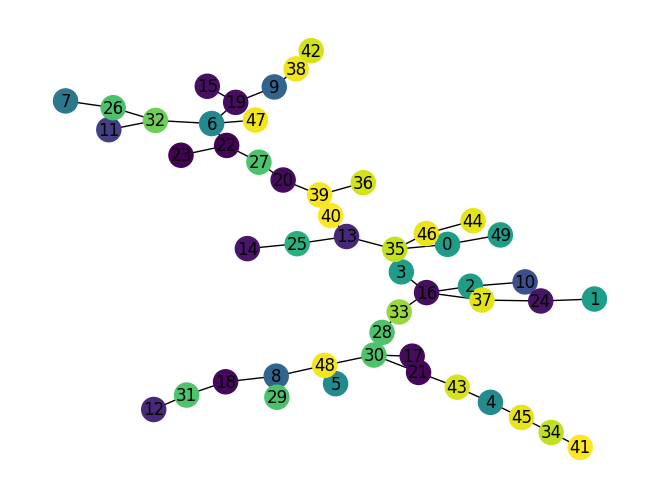

In [ ]:
tree = dfs_spanning_tree(graph)
gradient_graph(graph, tree)

In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [7]:
from qiskit_ibm_runtime.fake_provider import FakeTorino, FakeFez, FakeBrisbane

backend = FakeTorino()
# backend = FakeFez()
# backend = FakeBrisbane()
# use this if running on simulator
from qiskit_aer import AerSimulator

sim = AerSimulator().from_backend(backend)

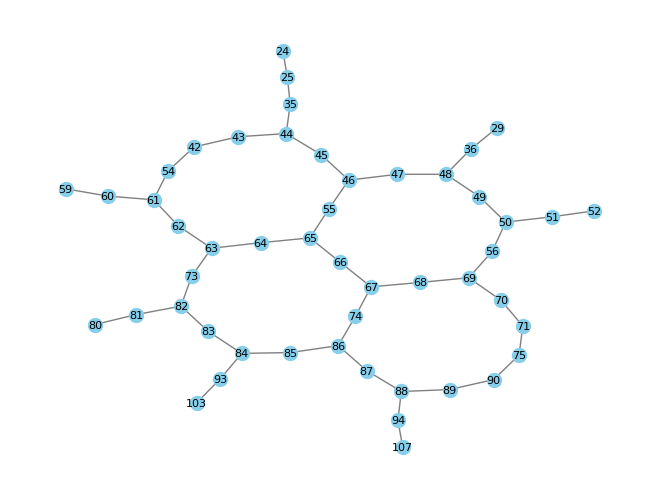

In [9]:
G = get_coupling_graph(backend)

# if not root_on_backend:
#     root_on_backend = backend.num_qubits//2
tree_layout = build_tree_cluster(G, source=backend.num_qubits//2, n=50)
draw_graph_custom(tree_layout, font_size=8)

In [8]:
def wraparound_spanning_tree(G):
    # 1. Start from a low-degree node (likely on the periphery)
    start = min(G.degree, key=lambda x: x[1])[0]

    # 2. Perform BFS from start and get the last visited node (furthest)
    bfs_nodes = list(nx.bfs_tree(G, source=start))
    end = bfs_nodes[-1]

    # 3. Shortest path from start to end (serves as "backbone")
    backbone_path = nx.shortest_path(G, source=start, target=end)
    print(start, end, len(backbone_path))

    # 4. Initialize tree with backbone edges
    T = nx.Graph()
    T.add_nodes_from(G.nodes)
    for u, v in zip(backbone_path, backbone_path[1:]):
        T.add_edge(u, v)

    # 5. BFS from all nodes in backbone to grow the tree and keep it connected
    visited = set(backbone_path)
    queue = list(backbone_path)
    order = []

    while queue:
        current = queue.pop(0)
        if current not in order:
            order.append(current)
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                T.add_edge(current, neighbor)
                visited.add(neighbor)
                queue.append(neighbor)
                order.append(neighbor)
    print(order)
    return T

tree = wraparound_spanning_tree(tree_layout)
draw_graph_custom(tree, font_size=8)
tree_re,re = relabel_02n(tree)
gradient_graph(tree_re)

NameError: name 'tree_layout' is not defined

In [9]:
import networkx as nx

def relabel_02n(G):
    # Create a mapping from old labels to new integer labels
    old_labels = list(G.nodes())
    mapping = {old_label: new_label for new_label, old_label in enumerate(old_labels)}
    
    # Relabel the graph
    G_relabelled = nx.relabel_nodes(G, mapping, copy=True)
    
    # Store the old labels as node attributes
    for new_label, old_label in mapping.items():
        G_relabelled.nodes[old_label]['old_label'] = new_label
    
    return G_relabelled, mapping  # Also return the mapping for reference

graph, old_to_new = relabel_02n(tree_layout)
draw_graph_custom(graph)

NameError: name 'tree_layout' is not defined

In [10]:

# Find the node with the minimum degree
degrees = tree_layout.degree()
min_node = min(degrees, key=lambda x: x[1])[0]
# dfs_nodes = list(nx.dfs_preorder_nodes(tree_layout, source=min_node))
tree = dfs_spanning_tree(tree_layout, root=min_node)
# tree = dfs_spanning_tree(tree_layout, root=backend.num_qubits//2)
print(nx.diameter(tree))
draw_graph_custom(tree)

NameError: name 'tree_layout' is not defined

In [11]:
tree, map = relabel_02n(tree)
gradient_graph(tree)
nx.distance

NameError: name 'tree' is not defined

In [12]:
rela

NameError: name 'rela' is not defined

In [13]:
backend.basis_gates

NameError: name 'backend' is not defined

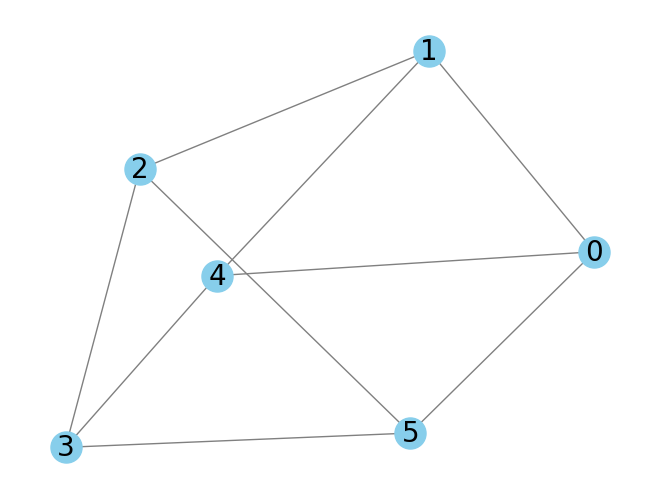

In [14]:
graph = nx.random_regular_graph(n=6, d=3, seed=0)
draw_graph_custom(graph, node_size=500, font_size=20)

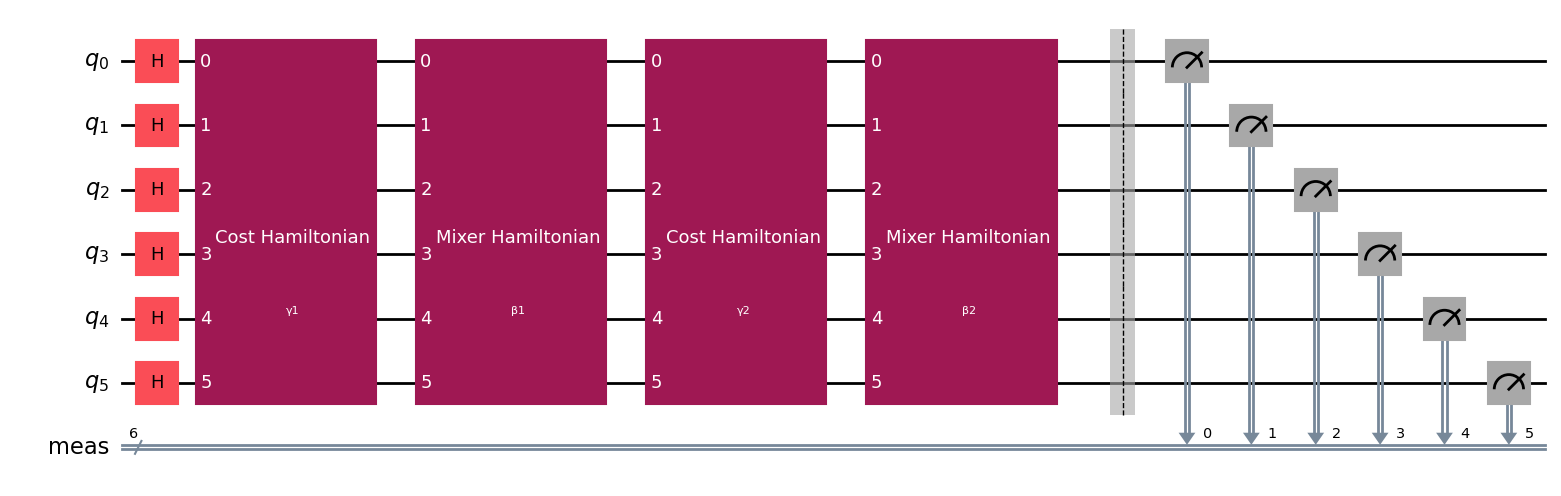

In [15]:
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.circuit import Parameter
graph = nx.random_regular_graph(n=6, d=3, seed=0)
ham = get_hamiltonian(graph)
gen = QuantumCircuit(6)
gen.h(range(6))
gamma = [Parameter('γ1'), Parameter('γ2')]
beta = [Parameter('β1'), Parameter('β2')]
evolution_gate = PauliEvolutionGate(ham, time=gamma[0], label='Cost Hamiltonian')
mixer_gate = PauliEvolutionGate(ham, time=beta[0], label='Mixer Hamiltonian')
evolution_gate_1 = PauliEvolutionGate(ham, time=gamma[1], label='Cost Hamiltonian')
mixer_gate_1 = PauliEvolutionGate(ham, time=beta[1], label='Mixer Hamiltonian')
gen.append(evolution_gate, gen.qubits)
gen.append(mixer_gate, gen.qubits)
gen.append(evolution_gate_1, gen.qubits)
gen.append(mixer_gate_1, gen.qubits)
gen.measure_all()
# gen = gen.decompose(reps=2)
gen.draw('mpl', fold=False)

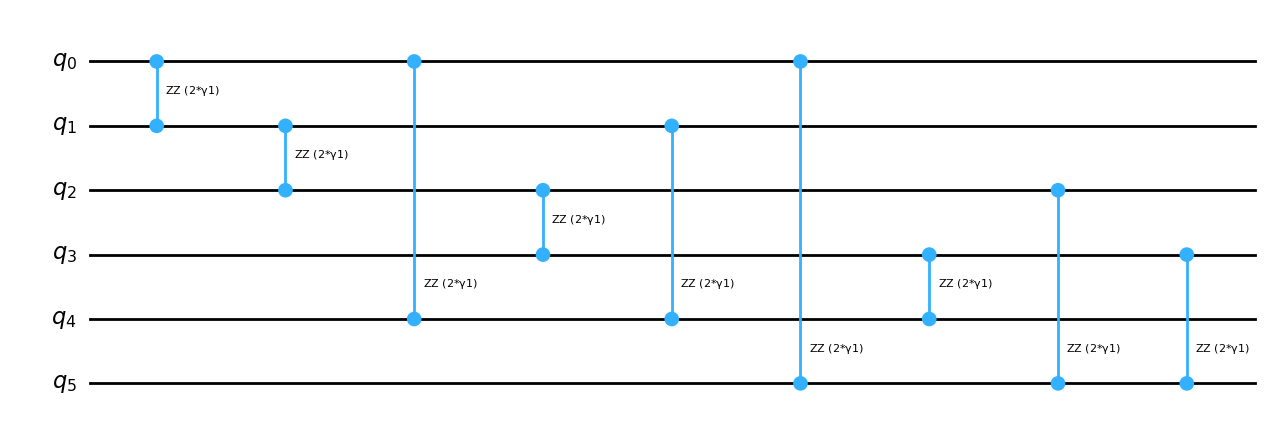

In [16]:
graph = nx.random_regular_graph(n=6, d=3, seed=0)
ham = get_hamiltonian(graph)
gen = QuantumCircuit(6)
# gen.h(range(6))
gamma = [Parameter('γ1'), Parameter('γ2')]
beta = [Parameter('β1'), Parameter('β2')]
evolution_gate = PauliEvolutionGate(ham, time=gamma[0], label='Cost Hamiltonian')
mixer_gate = PauliEvolutionGate(ham, time=beta[0], label='Mixer Hamiltonian')
evolution_gate_1 = PauliEvolutionGate(ham, time=gamma[1], label='Cost Hamiltonian')
mixer_gate_1 = PauliEvolutionGate(ham, time=beta[1], label='Mixer Hamiltonian')
gen.append(evolution_gate, gen.qubits)
# gen.append(mixer_gate, gen.qubits)
# gen.append(evolution_gate_1, gen.qubits)
# gen.append(mixer_gate_1, gen.qubits)
# gen.measure_all()
gen = gen.decompose(reps=1)
gen.draw('mpl', fold=False)

In [17]:
sim =AerSimulator()
# backend = FakeBrisbane()
# backend = FakeTorino()
backend = FakeFez()
# sim = AerSimulator().from_backend(backend)

NameError: name 'AerSimulator' is not defined

In [18]:
backend.basis_gates

NameError: name 'backend' is not defined

In [20]:

num_nodes=14
graph = nx.random_regular_graph(n=num_nodes, d=5, seed=0)

tree = dfs_spanning_tree(graph, root=num_nodes//2)

hamiltonian = get_hamiltonian(graph)
gen = gen_QAOA_circuit(graph, reps=1)
root_on_backend = backend.num_qubits//2

# Distribution with Proposed Initial Mapping
fied_mapping = initial_layout(tree, backend=backend, how='fiedler', topology='tree_dfs', root_on_backend=root_on_backend)
prop = custom_qaoa_ansatz(graph, fied_mapping, backend.coupling_map, reps=1)
opt_prop = final_optimized_circuit(prop, backend, fied_mapping, opt_level=3)

# Distribution with no explicit initial mapping set
opt_gen = final_optimized_circuit(gen_QAOA_circuit(graph, reps=1), backend, initial_mapping=None, opt_level=3)

op_name = 'cz'
print('Default=> ', f'{op_name}: ', opt_gen.count_ops().get(f'{op_name}', 0), 'Depth: ',opt_gen.depth())
# print('SABRE=> ',f'{op_name}: ', opt_sabre.count_ops().get(f'{op_name}', 0),'Depth: ', opt_sabre.depth())
print('Prop=> ', f'{op_name}: ', opt_prop.count_ops().get(f'{op_name}', 0), 'Depth: ',opt_prop.depth())

NameError: name 'backend' is not defined

In [21]:
params_prop = optimized_parameters(opt_prop, hamiltonian, sim, reps=1, shots=1000)
params_gen = optimized_parameters(opt_gen, hamiltonian, sim, reps=1, shots=1000)
print(params_gen)
print(params_prop)

NameError: name 'opt_prop' is not defined

In [22]:
results_2 = {'prop':sample_distribution(opt_prop, params_prop, sim, shots=1000), 'def':sample_distribution(opt_gen, params_gen, sim, shots=1000)}


NameError: name 'opt_prop' is not defined

In [23]:
results_3 = {'prop':sample_distribution(opt_prop, params_prop, sim, shots=1000), 'def':sample_distribution(opt_gen, params_prop, sim, shots=1000)}
results_4 = {'prop':sample_distribution(opt_prop, params_gen, sim, shots=1000), 'def':sample_distribution(opt_gen, params_gen, sim, shots=1000)}

NameError: name 'opt_prop' is not defined

In [24]:
results_2 = maxcut_dist(backend, backend, num_nodes=14, graph_type='reg', param=5, tree_type='dfs', reps=1, opt_level=3, estimator_shots=1000, sampler_shots=1000, want_sabre=False, op_name='ecr')

NameError: name 'backend' is not defined

In [25]:
most_likely_cut(results_2['def'])

NameError: name 'results_2' is not defined

In [26]:

# graph =  nx.random_regular_graph(n=14, d=5, seed=0)
dists = results_2
for key in dists.keys():
    if key!='sabre':
        print(key, ": ", evaluate_cut(graph, most_likely_cut(dists[key])))
# most_likely['rand'].append(evaluate_cut(graph, format(random.getrandbits(num_nodes), f'0{num_nodes}b')))

for key in dists.keys():
    if key!='sabre':    
        print(key, ": ",expected_size(graph, dists[key]))
# expected['rand'].append(random_size(graph, result['prop']))

NameError: name 'results_2' is not defined

In [27]:
print(max(results_2['prop'].values()), max(results_2['def'].values()))

NameError: name 'results_2' is not defined

In [28]:
from IPython.display import clear_output
backend=FakeFez()
# backend = FakeBrisbane()
# backend = FakeTorino()
# sim  = AerSimulator.from_backend(backend)

NameError: name 'FakeFez' is not defined

In [29]:
results_2 = []
num_nodes=10
tup = execution_ready_circuits(backend, num_nodes=num_nodes, graph_type='reg', param=5, tree_type='dfs', reps=1, opt_level=3, op_name='cz')

NameError: name 'backend' is not defined

In [30]:
tup[1].draw('mpl', fold=False)

NameError: name 'tup' is not defined

In [31]:
tup[2].draw('mpl', fold=False)

NameError: name 'tup' is not defined

In [32]:
def print_results(dists_list, num_nodes):
    most_likely = {'prop':[], 'def':[], 'rand':[]}
    expected = {'prop':[], 'def':[], 'rand':[]}
    graph = nx.random_regular_graph(n=num_nodes, d=5, seed=0)
    for result in dists_list:
        for key in most_likely.keys():
            if key!='rand':    
                most_likely[key].append(evaluate_cut(graph, most_likely_cut(result[key])))
        most_likely['rand'].append(evaluate_cut(graph, format(random.getrandbits(num_nodes), f'0{num_nodes}b')))

        for key in expected.keys():
            if key!='rand':    
                expected[key].append(expected_size(graph, result[key]))
        expected['rand'].append(random_size(graph, result['prop']))

    print('Most likely Cut size: ')
    for key in most_likely.keys():
        print(f"{key}-> Mean: {np.mean(most_likely[key])}, Std.Dev: {math.sqrt(np.var(most_likely[key]))}")

    print('\nExpected Cut size: ')
    for key in expected.keys():
        print(f"{key}-> Mean: {np.mean(expected[key])}, Std.Dev: {math.sqrt(np.var(expected[key]))}")

In [33]:
bakend = FakeFez()
sim = AerSimulator().from_backend(backend)

NameError: name 'FakeFez' is not defined

8

In [34]:
num_nodes=8
tup = execution_ready_circuits(backend, num_nodes=num_nodes, graph_type='reg', param=5, tree_type='dfs', reps=1, opt_level=3, op_name='cz')

NameError: name 'backend' is not defined

In [35]:
results_8 = return_dists(backend, tup[1], tup[2], tup[0], reps=1, estimator_shots=1000, sampler_shots=1000, runs=1)
print_results(results_8, num_nodes)

NameError: name 'backend' is not defined

10

In [36]:
backend = FakeBrisbane()

NameError: name 'FakeBrisbane' is not defined

exec -> 

In [37]:
num_nodes=12
tup = execution_ready_circuits(backend, num_nodes=num_nodes, graph_type='reg', param=5, tree_type='dfs', reps=1, opt_level=3, op_name='ecr')

NameError: name 'backend' is not defined

In [38]:
results_12 = return_dists(backend, tup[1], tup[2], tup[0], reps=1, estimator_shots=1000, sampler_shots=1000, runs=100)
print_results(results_12, num_nodes)

NameError: name 'backend' is not defined

In [39]:
print_results(results_12, num_nodes)

NameError: name 'results_12' is not defined

Most likely Cut size: 
prop-> Mean: 24.0, Std.Dev: 0.0
def-> Mean: 18.0, Std.Dev: 0.0
rand-> Mean: 14.0, Std.Dev: 0.0

Expected Cut size: 
prop-> Mean: 17.03099999999998, Std.Dev: 0.0
def-> Mean: 15.95599999999997, Std.Dev: 0.0
rand-> Mean: 16.735257214554583, Std.Dev: 0.0

16

In [40]:
num_nodes=16
tup = execution_ready_circuits(backend, num_nodes=num_nodes, graph_type='reg', param=5, tree_type='dfs', reps=1, opt_level=3, op_name='ecr')

NameError: name 'backend' is not defined

In [41]:
results_16 = return_dists(backend, tup[1], tup[2], tup[0], reps=1, estimator_shots=1000, sampler_shots=1000, runs=1)
print_results(results_16, num_nodes)

NameError: name 'backend' is not defined

In [42]:
num_nodes=16
tup = execution_ready_circuits(backend, num_nodes=num_nodes, graph_type='reg', param=5, tree_type='dfs', reps=1, opt_level=3, op_name='cz')

NameError: name 'backend' is not defined

In [43]:
results_16 = return_dists(backend, tup[1], tup[2], tup[0], reps=1, estimator_shots=1000, sampler_shots=1000, runs=1)
print_results(results_16, num_nodes)

NameError: name 'backend' is not defined

16

In [44]:
import itertools
import networkx as nx

def mean_cut_size(graph):
    """
    Computes the mean cut size over all possible bitstrings for a given graph.
    
    Args:
        graph: Either a NetworkX Graph object or a list of edges [(u, v), ...].
        
    Returns:
        The mean cut size (float).
    """
    if not isinstance(graph, nx.Graph):
        g = nx.Graph()
        g.add_edges_from(graph)
    else:
        g = graph
    n = g.number_of_nodes()
    nodes = list(g.nodes())
    edge_list = list(g.edges())
    total_cuts = 0
    num_bitstrings = 2 ** n

    for bitstring in itertools.product([0, 1], repeat=n):
        assignment = dict(zip(nodes, bitstring))
        cut = 0
        for u, v in edge_list:
            if assignment[u] != assignment[v]:
                cut += 1
        total_cuts += cut

    mean = total_cuts / num_bitstrings
    return mean
mean_cut_size(nx.random_regular_graph(n=12, d=5, seed=0))

15.0

In [45]:
show_histograms(results_10[-1], num_plots=2, y_lim=0.01)

NameError: name 'results_10' is not defined

In [46]:
from IPython.display import clear_output

results = []
num_nodes=14
for i in tqdm(range(100)):
    results.append(maxcut_dist(sim, backend, num_nodes=num_nodes, graph_type='reg', param=5, tree_type='dfs', reps=1, opt_level=3, estimator_shots=1000, sampler_shots=1000, want_sabre=False, op_name='ecr'))
    clear_output(wait=True)

  0%|          | 0/100 [00:00<?, ?it/s]


NameError: name 'sim' is not defined

Most likely Cut size: 
prop-> Mean: 25.62, Std.Dev: 1.3174217244299564
def-> Mean: 25.96, Std.Dev: 0.9156418513807676
rand-> Mean: 17.9, Std.Dev: 2.9916550603303187

Expected Cut size: 
prop-> Mean: 20.0337239999988, Std.Dev: 0.2786463267728073
def-> Mean: 20.222834999998767, Std.Dev: 0.1174405061084005
rand-> Mean: 19.130988969200178, Std.Dev: 0.18750698756917322

In [47]:
from collections import defaultdict

def compute_mean_distributions(distribution_list):
    # Collectors
    accumulator = defaultdict(lambda: defaultdict(float))
    counts = defaultdict(int)

    for item in distribution_list:
        for label, dist in item.items():
            counts[label] += 1
            for bitstring, prob in dist.items():
                accumulator[label][bitstring] += prob

    # Average the values
    mean_result = {}
    for label, dist in accumulator.items():
        mean_result[label] = {
            bitstring: prob_sum / counts[label] for bitstring, prob_sum in dist.items()
        }

    return mean_result
mean_dist = compute_mean_distributions(results_12)

NameError: name 'results_12' is not defined

In [48]:
print(max(mean_dist['prop'].values()), max(mean_dist['def'].values()))

NameError: name 'mean_dist' is not defined

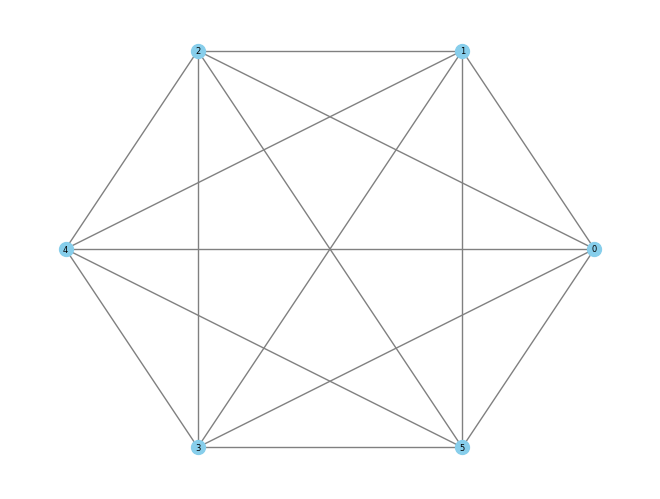

In [49]:
draw_graph_custom(nx.random_regular_graph(n=6, d=5, ))

In [50]:
# show_histograms(result, num_plots=2, y_lim=0.005, keep_top=500)
show_histograms(mean_dist, num_plots=2, y_lim=0.005)

NameError: name 'mean_dist' is not defined

In [51]:
show_histograms(mean_dist, num_plots=2, y_lim=0.005, keep_top=100)

NameError: name 'mean_dist' is not defined

In [52]:
show_histograms(mean_dist, num_plots=2, y_lim=0.0045)

NameError: name 'mean_dist' is not defined

In [53]:
def plot_bar_graph(data_dict, title='Bar Graph', xlabel='Keys', ylabel='Values'):
    """
    Plots a bar graph for a dictionary with float values.

    Args:
        data_dict (dict): Dictionary with keys as categories (str) and float values.
        title (str): Title of the graph.
        xlabel (str): Label for x-axis.
        ylabel (str): Label for y-axis.
    """
    keys = list(data_dict.keys())
    values = list(data_dict.values())
    print(max(values))

    plt.figure(figsize=(10, 6))
    plt.bar(keys, values)
    plt.xticks(rotation=45, ha='right')
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    # plt.tight_layout()
    plt.show()

plot_bar_graph(mean_dist['prop'])

NameError: name 'mean_dist' is not defined

In [54]:
graph = nx.random_regular_graph(n=20, d=5, seed=0)
tree = dfs_spanning_tree(graph, root=0)

# fied_mapping = initial_layout(tree, backend, topology='chain')
# prop = custom_qaoa_ansatz(graph, fied_mapping, backend.coupling_map, 1)
gen = gen_QAOA_circuit(graph, reps=1)

In [55]:
gen = gen.decompose(reps=1)
# gen.draw('mpl', fold=False)

In [56]:
chain = find_linear_chain(backend, 20)
mapping = initial_layout(graph, backend)
mapping_layout = Layout({q: mapping[i] for i,q in enumerate(gen.qubits)})
chain

NameError: name 'backend' is not defined

In [57]:
graph = nx.random_regular_graph(n=100, d=3, seed=0)
gen = gen_QAOA_circuit(graph, reps=1)
gen = gen.decompose(reps=1)
sorted_nodes = fiedler_sort(graph)
sorted_nodes

NameError: name 'fiedler_sort' is not defined

In [58]:
from qiskit.transpiler.passes.routing.commuting_2q_gate_routing import (
    SwapStrategy,
    FindCommutingPauliEvolutions,
    Commuting2qGateRouter,
)
# swap_strat = SwapStrategy.from_line(sorted_nodes)
swap_strat = SwapStrategy.from_line(list(range(100)))
# mapping_layout = Layout({q: chain[i] for i,q in enumerate(gen.qubits)})
pm_pre = PassManager(
    [
        FindCommutingPauliEvolutions(),
        Commuting2qGateRouter(swap_strategy=swap_strat),
        # SetLayout(mapping_layout),
        # SabreLayout(backend.coupling_map, skip_routing=True, seed=0),
        # FullAncillaAllocation(backend.coupling_map),
        # EnlargeWithAncilla(),
        # ApplyLayout(),
    ])
# basis_change = transpile(gen, basis_gates=backend.basis_gates, optimization_level=3, seed_transpiler=0)
t = pm_pre.run(gen)
# t.draw('mpl', fold=False)
t.count_ops().get('swap', 0)

4802

In [59]:
t.count_ops().get('swap', 0)
# t.depth()

4802

In [60]:
sabre_routed_circuit(gen, backend, reps=1).count_ops().get('swap', 0)

NameError: name 'backend' is not defined

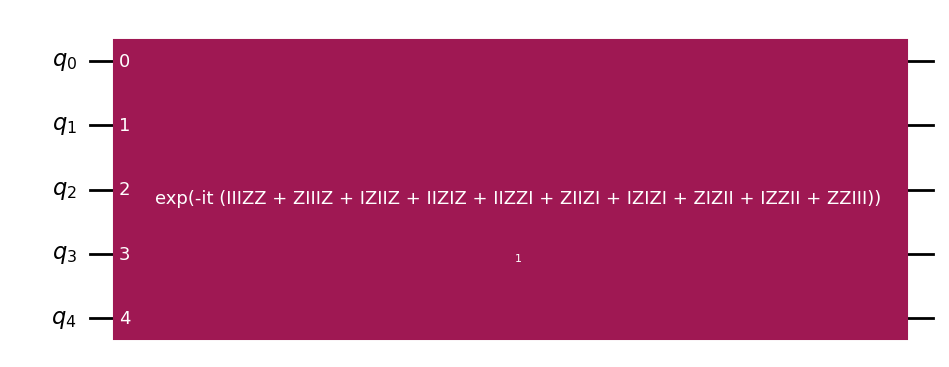

In [61]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import Layout, CouplingMap, PassManager
from qiskit.transpiler.passes import FullAncillaAllocation
from qiskit.transpiler.passes import EnlargeWithAncilla
from qiskit.transpiler.passes import ApplyLayout
from qiskit.transpiler.passes import SetLayout
 
from qiskit.transpiler.passes.routing.commuting_2q_gate_routing import (
    SwapStrategy,
    FindCommutingPauliEvolutions,
    Commuting2qGateRouter,
)
graph = nx.random_regular_graph(n=5, d=4, seed=0)
pauli = build_max_cut_paulis(graph)
# Define the circuit on virtual qubits
op = SparsePauliOp.from_list(pauli)
circ = QuantumCircuit(5)
circ.append(PauliEvolutionGate(op, 1), range(5))
circ.draw('mpl', fold=False)


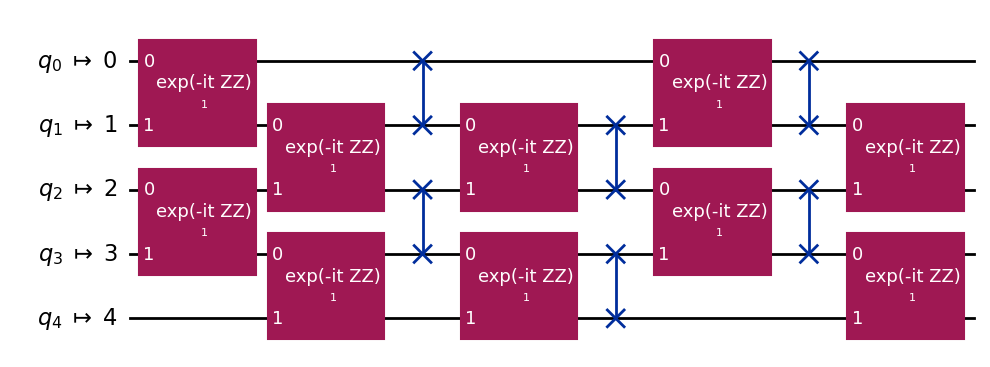

In [62]:
# Define the swap strategy on qubits before the initial_layout is applied.
swap_strat = SwapStrategy.from_line([0, 1, 2, 3,4])
 
# Chose qubits 0, 1, 3, and 4 from the backend coupling map shown above.
backend_cmap = CouplingMap(couplinglist=[(0, 1), (1, 2), (1, 3), (3, 4),(4,5)])
initial_layout = Layout.from_intlist([0, 1, 3, 4,5], *circ.qregs)
 
pm_pre = PassManager(
    [
        FindCommutingPauliEvolutions(),
        Commuting2qGateRouter(swap_strat),
        # SetLayout(initial_layout),
        # FullAncillaAllocation(backend_cmap),
        # EnlargeWithAncilla(),
        # ApplyLayout(),
    ]
)
 
# Insert swap gates, map to initial_layout and finally enlarge with ancilla.
pm_pre.run(circ).draw("mpl")

In [63]:
preset_pm.expanded_stages

NameError: name 'preset_pm' is not defined

In [64]:
preset_pm.post_layout.to_flow_controller().passes

NameError: name 'preset_pm' is not defined

In [65]:
preset_pm.layout.to_flow_controller().tasks

NameError: name 'preset_pm' is not defined

C:\Users\devra\AppData\Local\Temp\ipykernel_18868\69950173.py:175: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  adj_matrix = nx.adjacency_matrix(tree).todense()


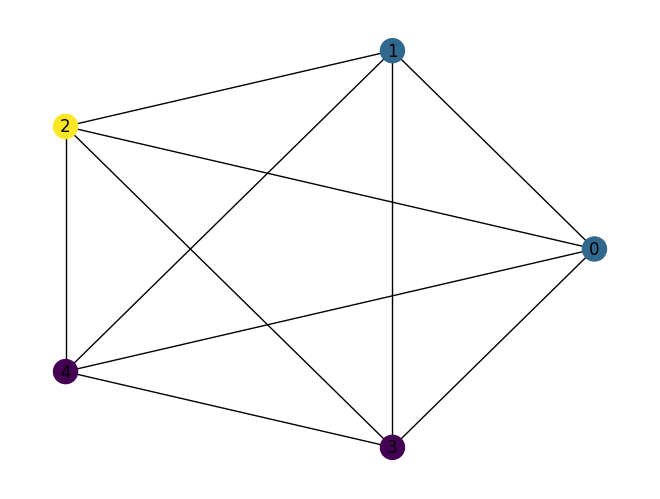

In [66]:
gradient_graph(graph)

In [67]:
t = preset_pm.run(gen)

NameError: name 'preset_pm' is not defined

### Swaps on Regular Graphs

In [85]:
from qiskit_ibm_runtime.fake_provider import FakeTorino, FakeFez, FakeBrisbane
backend = FakeFez()

In [86]:
import matplotlib.pyplot as plt

nodes = list(range(6, 101, 2))
params = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, tree_type='dfs',
                         average_over=10, node_list=nodes,
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

Iterating for number of nodes:   0%|          | 0/48 [00:00<?, ?it/s]C:\Users\devra\AppData\Local\Temp\ipykernel_18868\69950173.py:209: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  adj_matrix = nx.adjacency_matrix(graph, nodelist=range(graph.number_of_nodes())).todense()


TypeError: sabre_routed_circuit() got an unexpected keyword argument 'initial_mapping'

In [70]:
nodes = list(range(6, 101, 2))
params = list(range(3,6,1))
for param in params:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        if s!='Random':
            plt.plot(nodes, swaps_reg[param][s], label=s)

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title(f"SWAPs vs Number of Nodes\nFor {param}-regular graphs")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend( fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

KeyError: 3

<Figure size 800x500 with 0 Axes>

In [71]:
nodes = list(range(6, 31, 2))
params = list(range(3,6,1))
for param in params:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        if s!='Random':
            plt.plot(nodes, swaps_reg[param][s][:13], label=s)

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title(f"SWAPs vs Number of Nodes\nFor {param}-regular graphs")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend( fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

KeyError: 3

<Figure size 800x500 with 0 Axes>

In [72]:
import matplotlib.pyplot as plt

nodes = list(range(6, 101, 2))
params = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, tree_type='dfs',
                         average_over=5, node_list=nodes,
                         topology='tree', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

NameError: name 'backend' is not defined

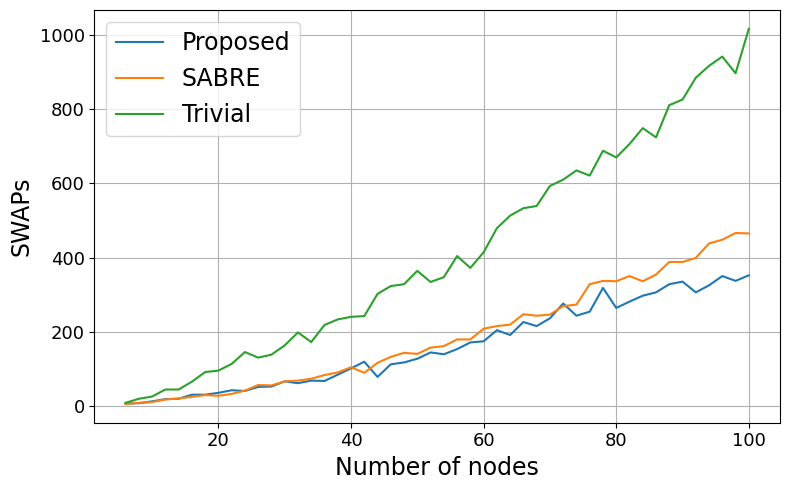

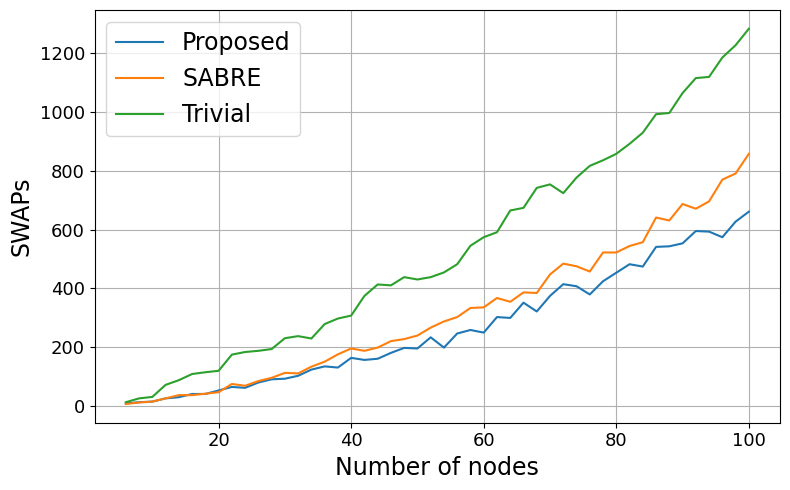

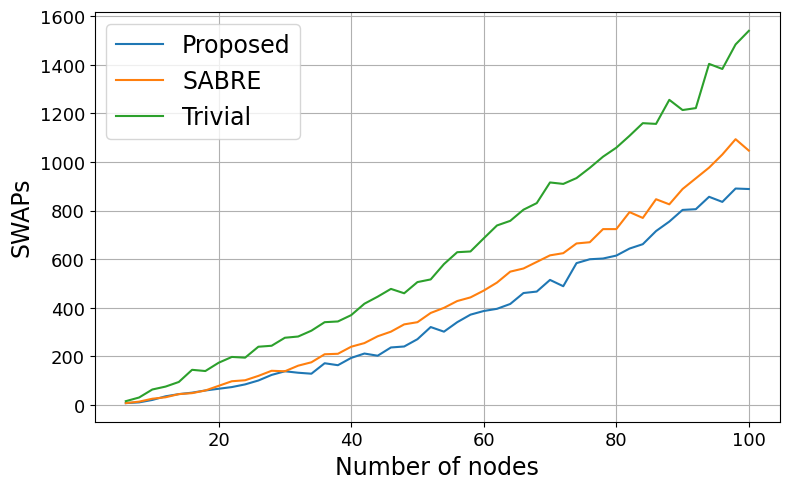

In [153]:
nodes = list(range(6, 101, 2))
params = list(range(3,6,1))
for param in params:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        if s!='Random':
            plt.plot(nodes, swaps_reg[param][s], label=s)

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title(f"SWAPs vs Number of Nodes\nFor {param}-regular graphs")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend( fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

### Depths after Routing on Regular Graphs

In [118]:
nodes = list(range(6, 101, 2))
params = list(range(3,6,1))
swap_depths_reg={}
for param in params:
    swap_depths_reg[param] = return_depths(backend, graph_type='reg', param=param, tree_type='dfs',
                         average_over=5, node_list=nodes,
                         topology='tree', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

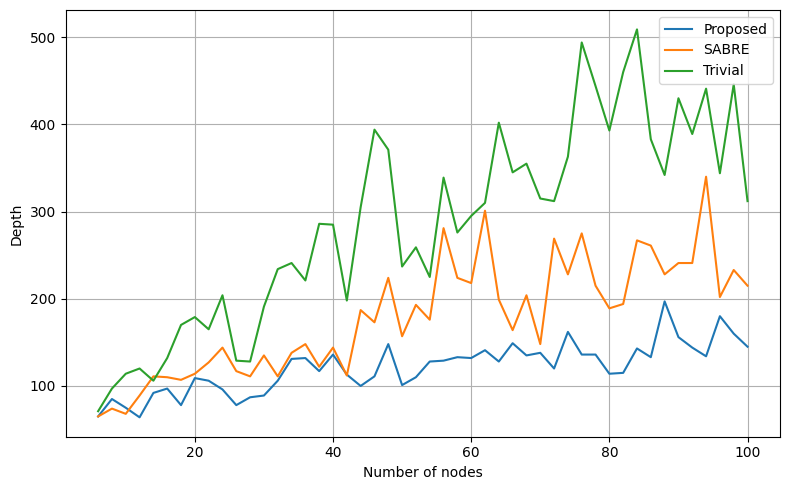

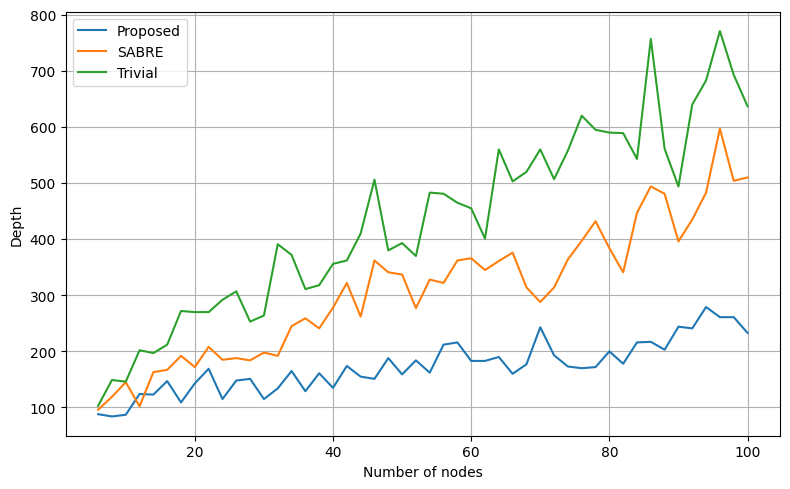

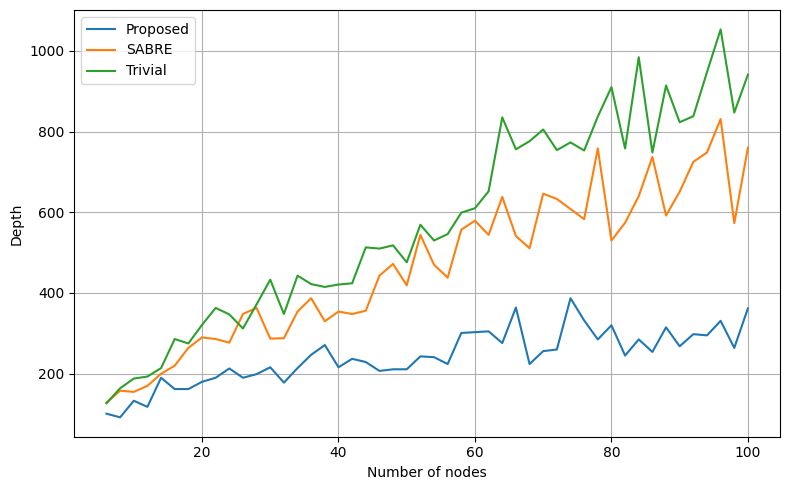

In [144]:
nodes = list(range(6, 101, 2))
params = list(range(3,6,1))
for param in params:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        if s!='Random':
            plt.plot(nodes, swap_depths_reg[param][s], label=s)

    plt.xlabel("Number of nodes")
    plt.ylabel("Depth")
    # plt.title(f"Depth vs Number of Nodes (param = {param})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

### 2-Qubit Gates in final circuits in Regular Graphs

In [548]:
nodes = list(range(6, 101, 2))
params = list(range(3,6,1))
czs_reg={}
for param in params:
    czs_reg[param] = return_ops(backend, graph_type='reg', param=param, tree_type='dfs',
                         average_over=5, node_list=nodes,
                         topology='tree_dfs', op_name='cz', use_custom=True, reps=1, opt_level=0)

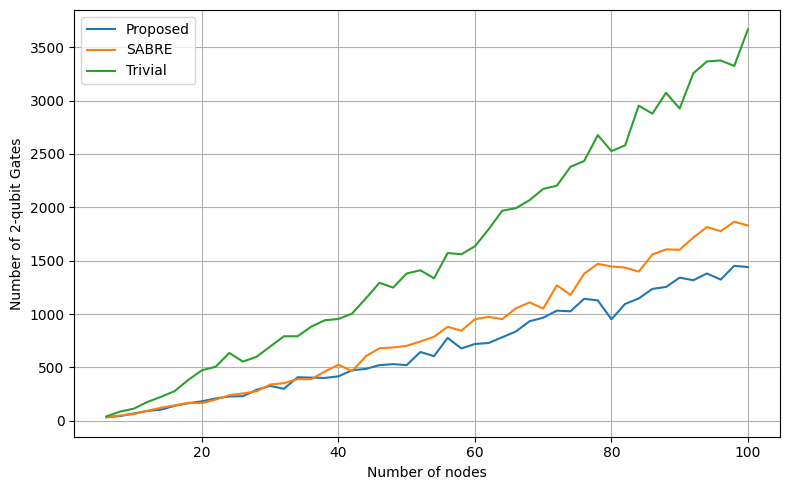

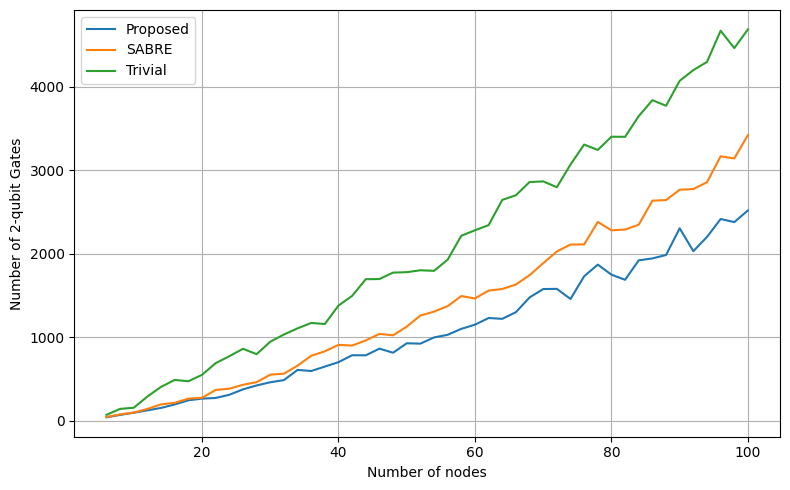

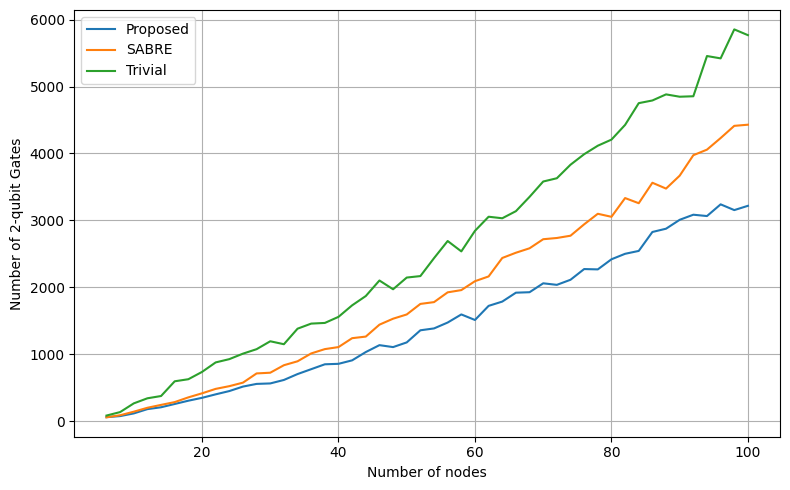

In [549]:
nodes = list(range(6, 101, 2))
params = list(range(3,6,1))
for param in params:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        if s!='Random':
            plt.plot(nodes, czs_reg[param][s], label=s)

    plt.xlabel("Number of nodes")
    plt.ylabel("Number of 2-qubit Gates")
    # plt.title(f"Depth vs Number of Nodes (param = {param})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

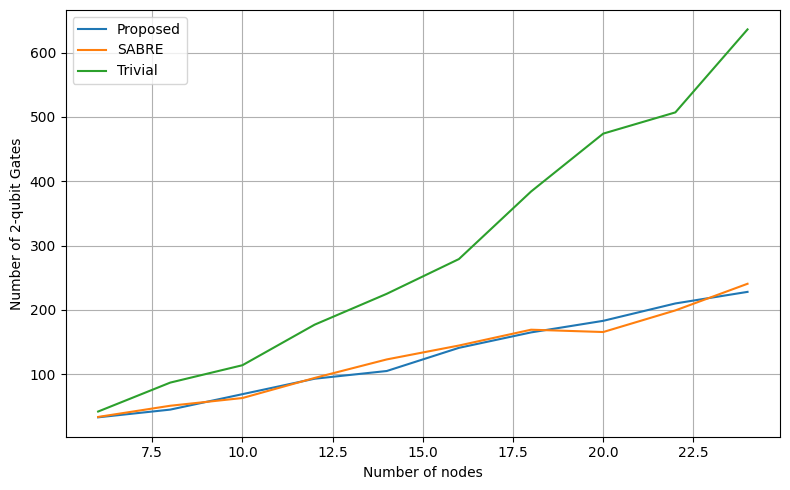

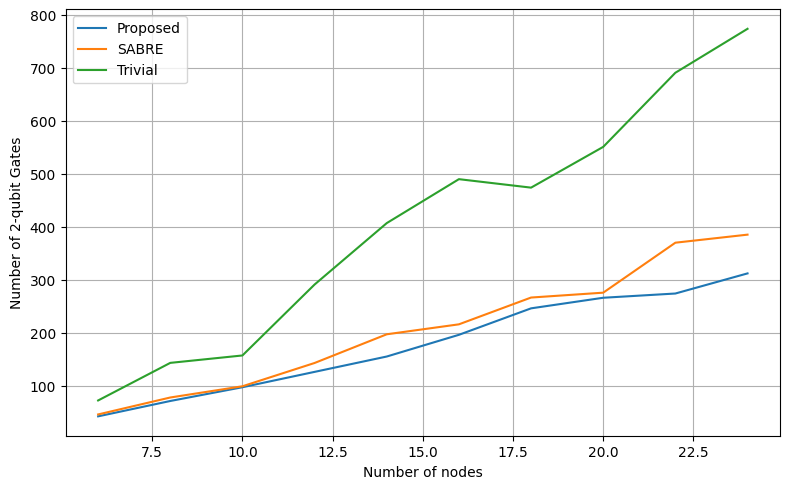

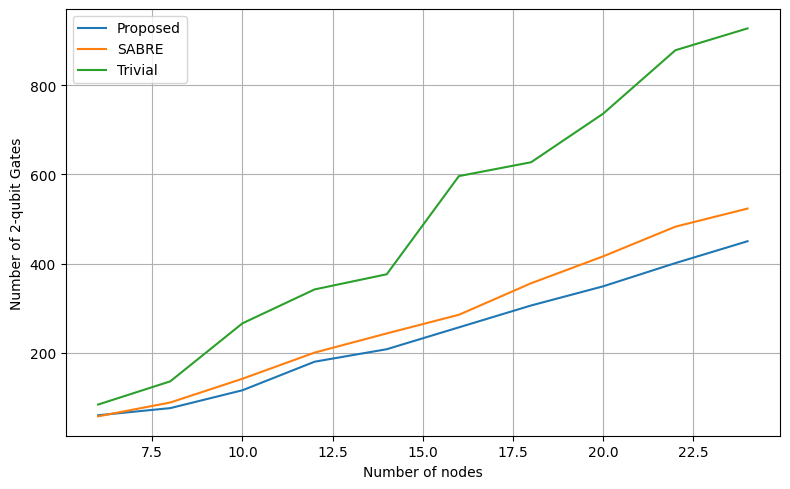

In [550]:
# nodes = list(range(6, 101, 2))
nodes = list(range(6,25, 2))
params = list(range(3,6,1))
for param in params:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        if s!='Random':
            plt.plot(nodes, czs_reg[param][s][:10], label=s)

    plt.xlabel("Number of nodes")
    plt.ylabel("Number of 2-qubit Gates")
    # plt.title(f"Depth vs Number of Nodes (param = {param})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [130]:
nodes = list(range(6, 101, 2))
params = list(range(3,6,1))
czs_reg={}
for param in params:
    czs_reg[param] = return_ops(backend, graph_type='reg', param=param, tree_type='dfs',
                         average_over=5, node_list=nodes,
                         topology='tree', op_name='cz', use_custom=True, reps=1)

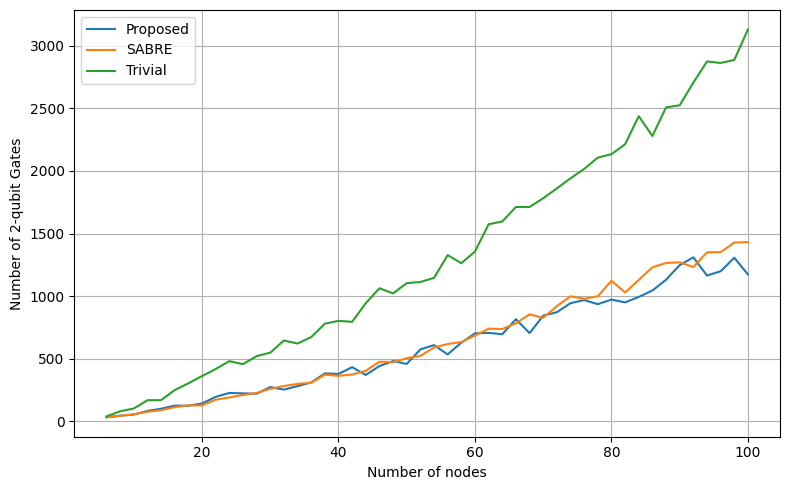

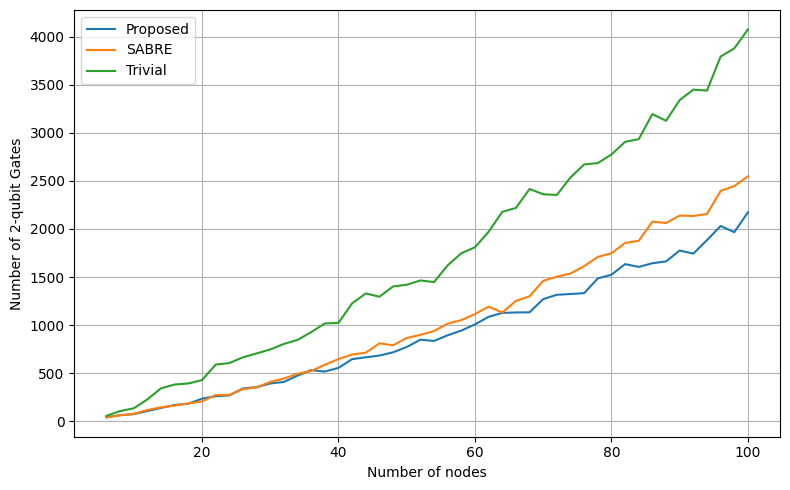

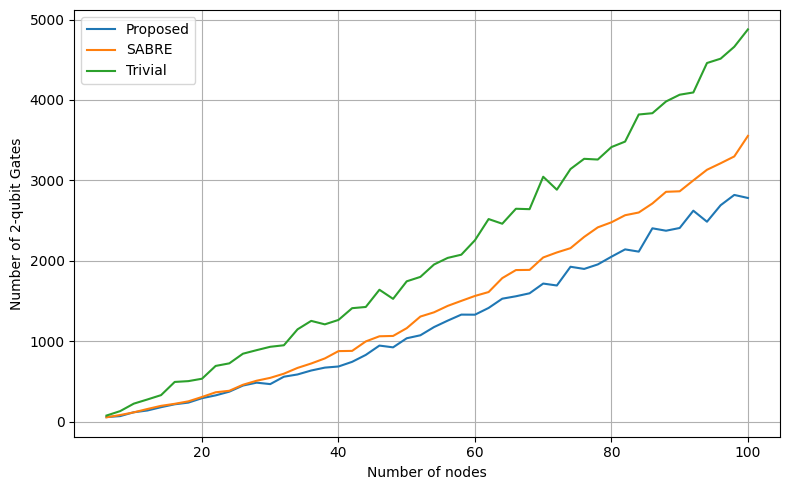

In [131]:
nodes = list(range(6, 101, 2))
params = list(range(3,6,1))
for param in params:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        if s!='Random':
            plt.plot(nodes, czs_reg[param][s], label=s)

    plt.xlabel("Number of nodes")
    plt.ylabel("Number of 2-qubit Gates")
    # plt.title(f"Depth vs Number of Nodes (param = {param})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [121]:
nodes = list(range(6, 101, 2))
params = list(range(3,6,1))
czs_reg={}
for param in params:
    czs_reg[param] = return_ops(backend, graph_type='reg', param=param, tree_type='dfs',
                         average_over=5, node_list=nodes,
                         topology='tree', op_name='cz', use_custom=True, reps=1)

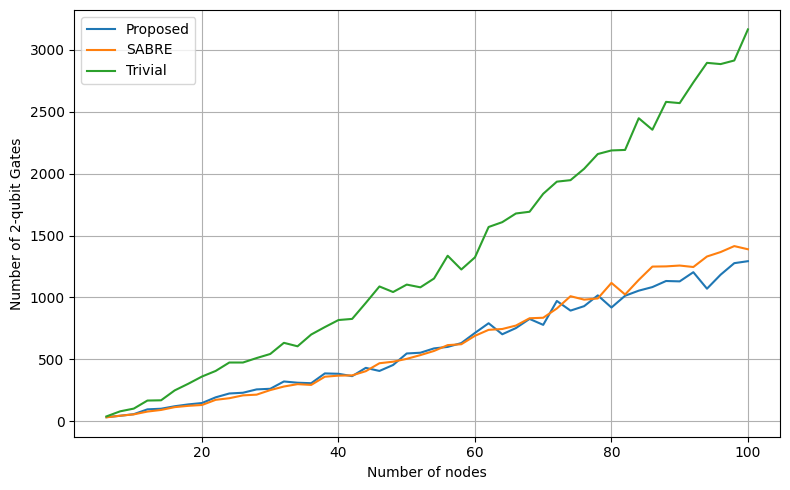

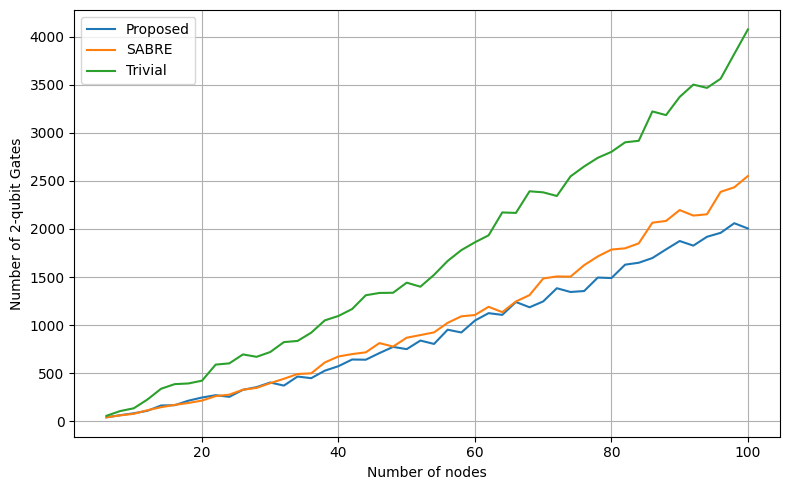

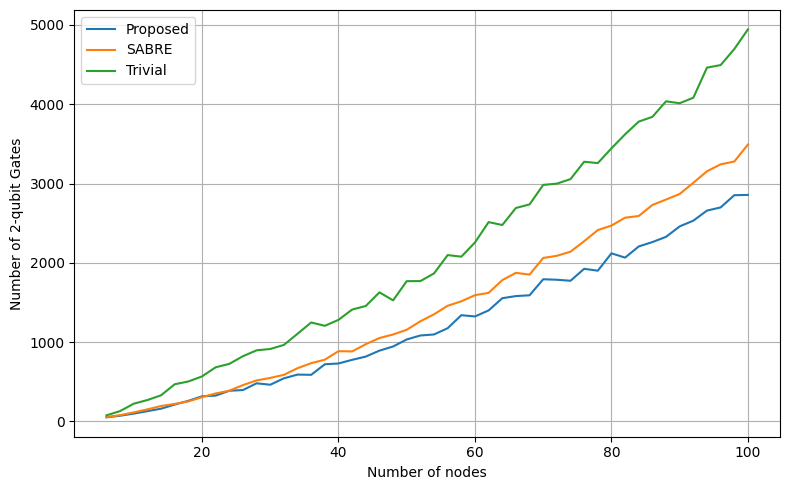

In [145]:
nodes = list(range(6, 101, 2))
params = list(range(3,6,1))
for param in params:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        if s!='Random':
            plt.plot(nodes, czs_reg[param][s], label=s)

    plt.xlabel("Number of nodes")
    plt.ylabel("Number of 2-qubit Gates")
    # plt.title(f"Depth vs Number of Nodes (param = {param})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

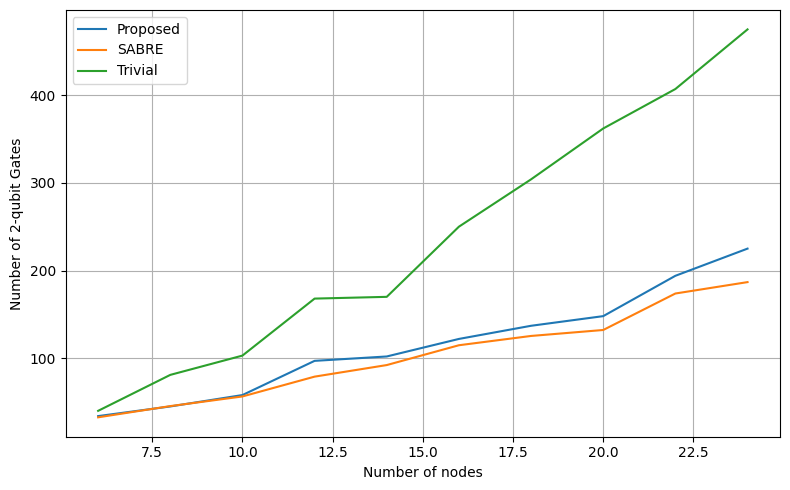

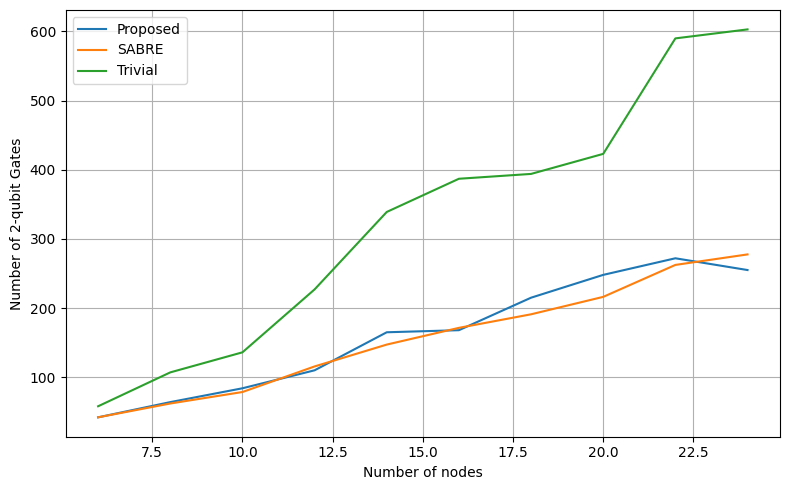

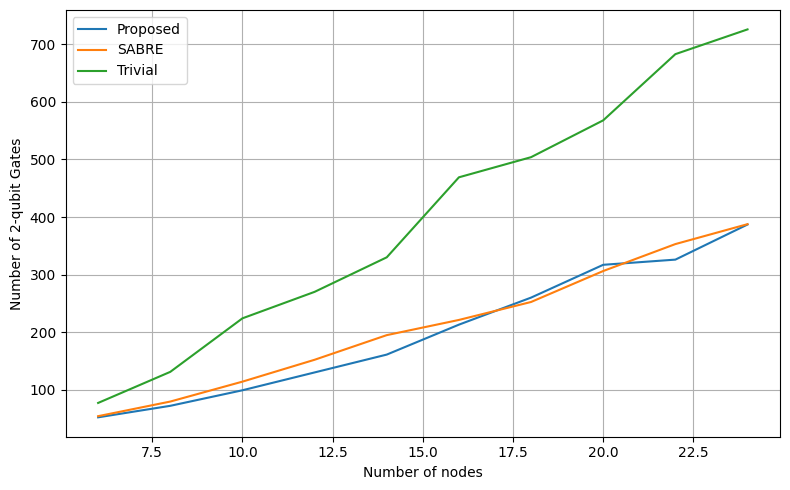

In [155]:
# nodes = list(range(6, 101, 2))
nodes = list(range(6,25, 2))
params = list(range(3,6,1))
for param in params:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        if s!='Random':
            plt.plot(nodes, czs_reg[param][s][:10], label=s)

    plt.xlabel("Number of nodes")
    plt.ylabel("Number of 2-qubit Gates")
    # plt.title(f"Depth vs Number of Nodes (param = {param})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

### Depths of Final Circuits for Regular Graphs

In [123]:
nodes = list(range(6, 101, 2))
params = list(range(3,6,1))
depths_reg={}
for param in params:
    depths_reg[param] = return_depths(backend, graph_type='reg', param=param, tree_type='dfs',
                         average_over=5, node_list=nodes,
                         topology='tree', use_custom=True, opt_level=3, reps=1)

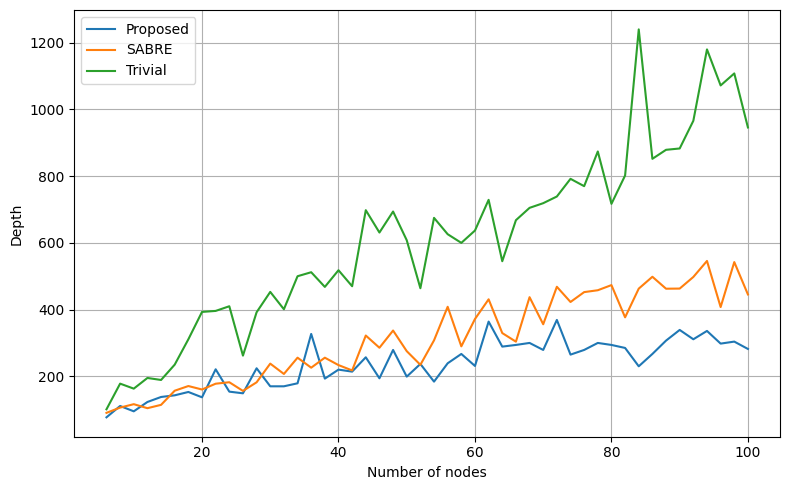

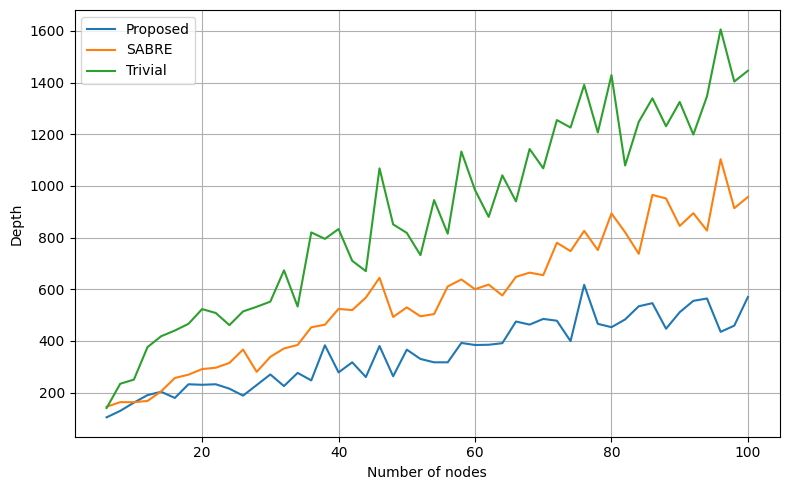

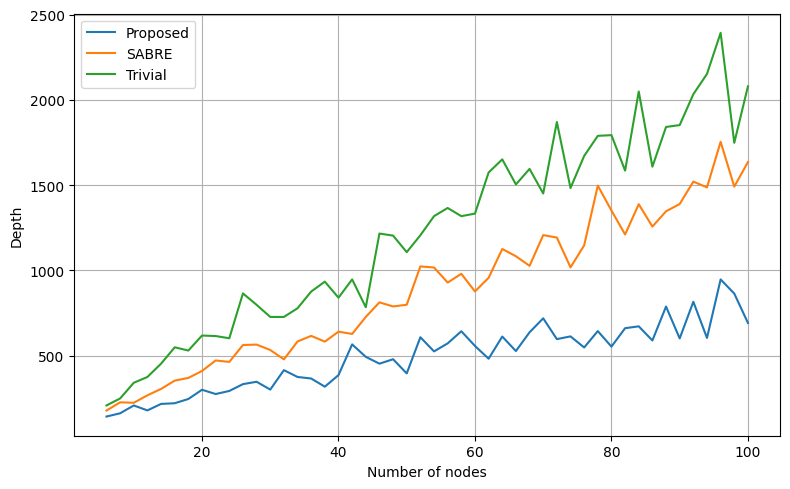

In [146]:
nodes = list(range(6, 101, 2))
params = list(range(3,6,1))
for param in params:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        if s!='Random':
            plt.plot(nodes, depths_reg[param][s], label=s)

    plt.xlabel("Number of nodes")
    plt.ylabel("Depth")
    # plt.title(f"Depth vs Number of Nodes (param = {param})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

### Swaps on BA Graphs

In [127]:
import matplotlib.pyplot as plt

nodes = list(range(6, 101, 2))
params = list(range(1,5,1))
# params = [5]
swaps_ba={}
for param in params:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param, tree_type='dfs',
                         average_over=5, node_list=nodes,
                         topology='tree', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

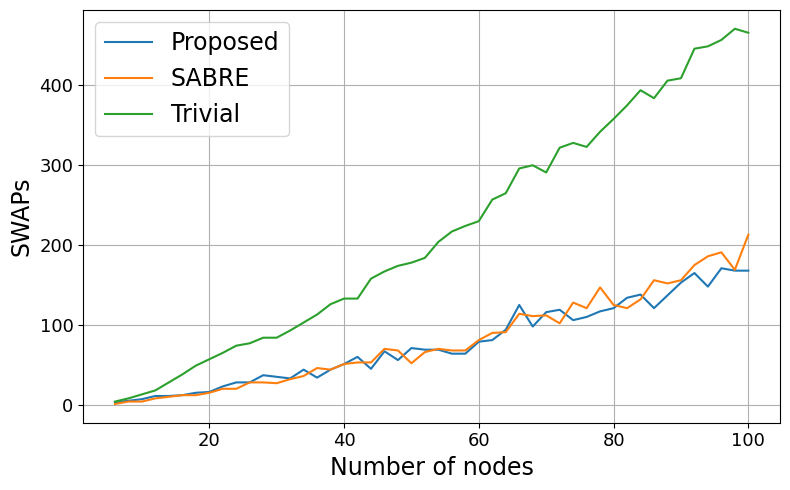

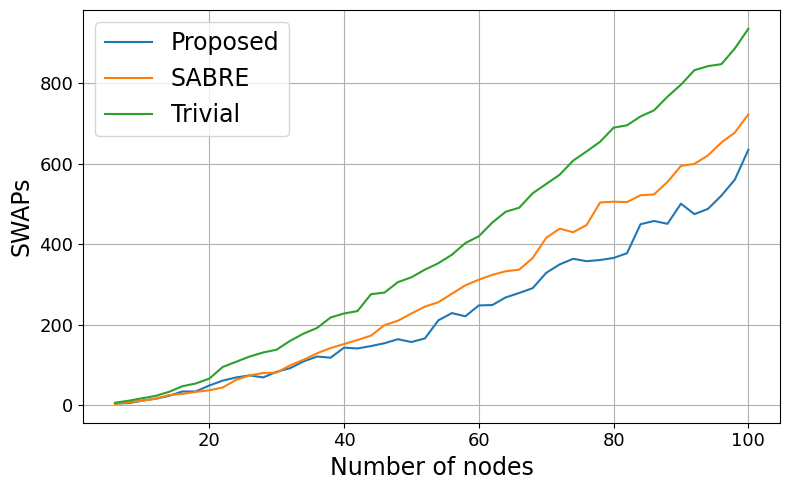

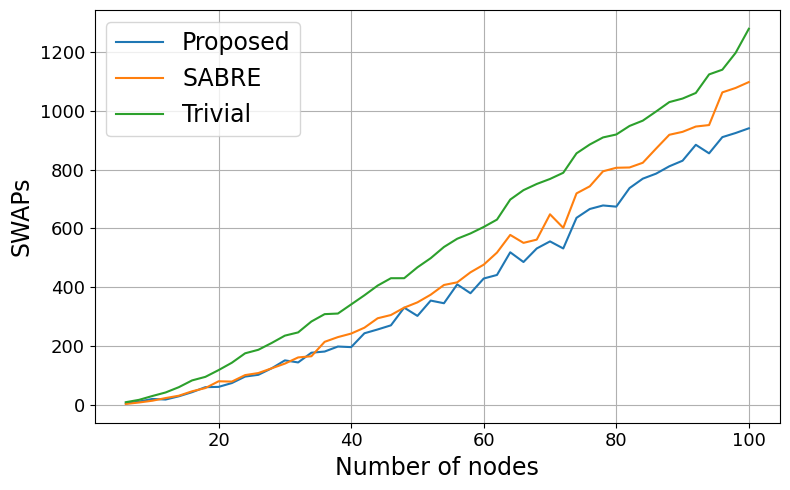

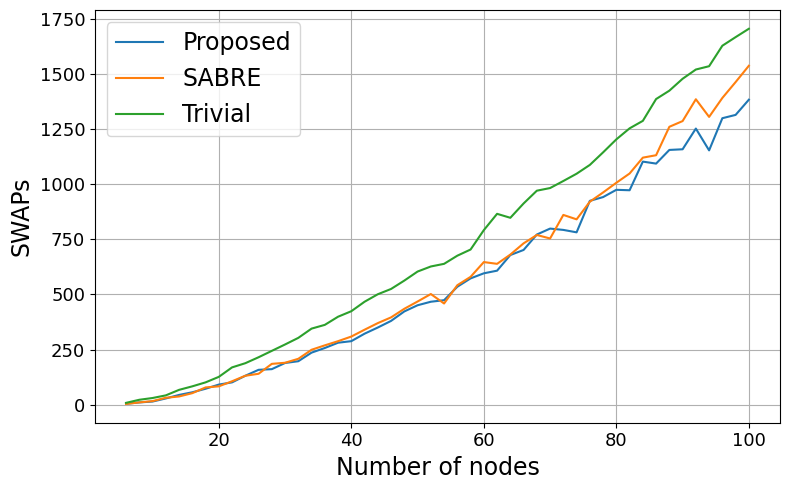

In [152]:
nodes = list(range(6, 101, 2))
params = list(range(1,5,1))
for param in params:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        if s!='Random':
            plt.plot(nodes, swaps_ba[param][s], label=s)

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title(f"SWAPs vs Number of Nodes (param = {param})")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

### Depths after Routing on BA Graphs

In [131]:
nodes = list(range(6, 101, 2))
params = list(range(1,5,1))
swap_depths_ba={}
for param in params:
    swap_depths_ba[param] = return_depths(backend, graph_type='ba', param=param, tree_type='dfs',
                         average_over=5, node_list=nodes,
                         topology='tree', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

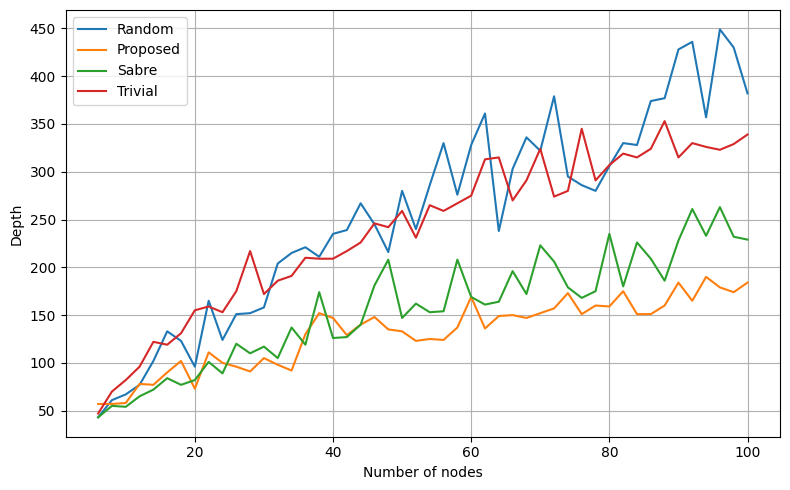

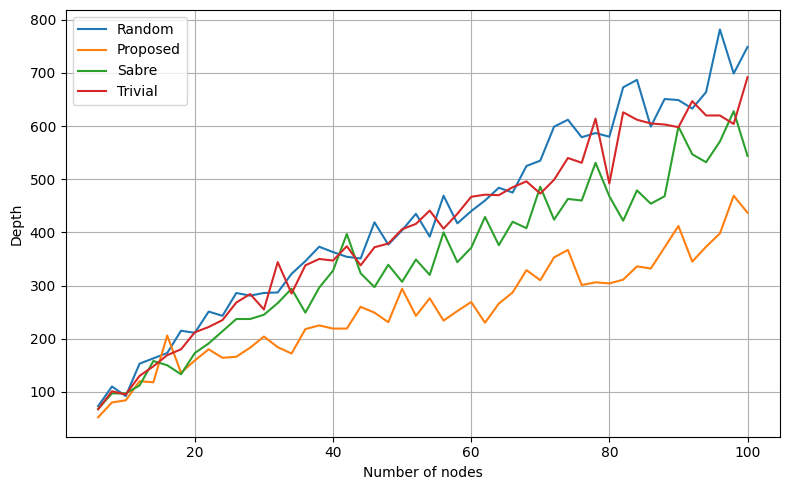

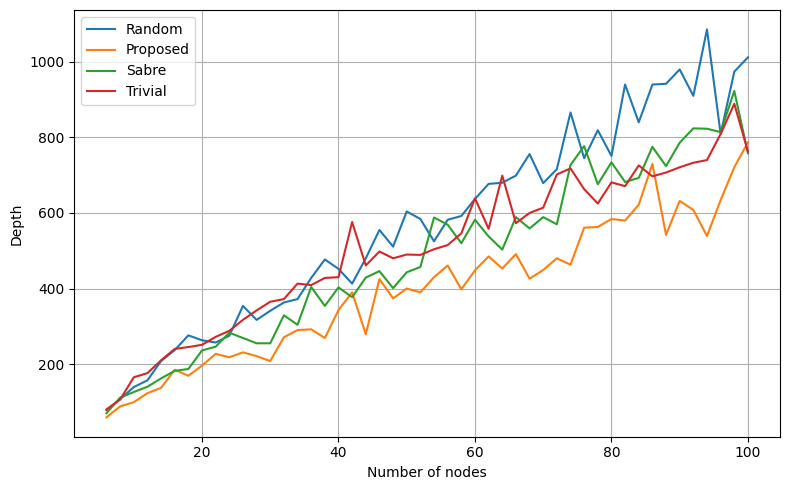

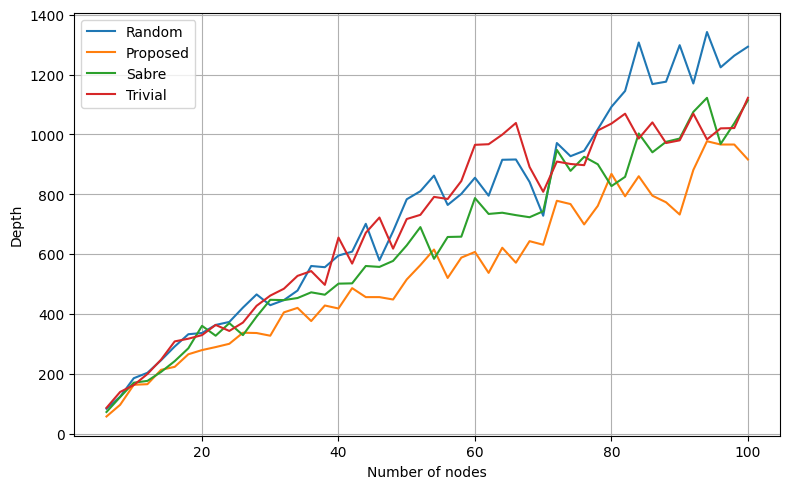

In [132]:
nodes = list(range(6, 101, 2))
params = list(range(1,5,1))
for param in params:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        plt.plot(nodes, swap_depths_ba[param][s], label=s.capitalize())

    plt.xlabel("Number of nodes")
    plt.ylabel("Depth")
    # plt.title(f"Depth vs Number of Nodes (param = {param})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

### 2-Qubit Gates in final circuits in BA Graphs

In [133]:
nodes = list(range(10,101,5))
params = list(range(1,5,1))
czs_ba={}
for param in params:
    czs_ba[param] = return_ops(backend, graph_type='ba', param=param, tree_type='dfs',
                         average_over=1, node_list=nodes,
                         topology='tree', op_name='cz', use_custom=True, reps=1)

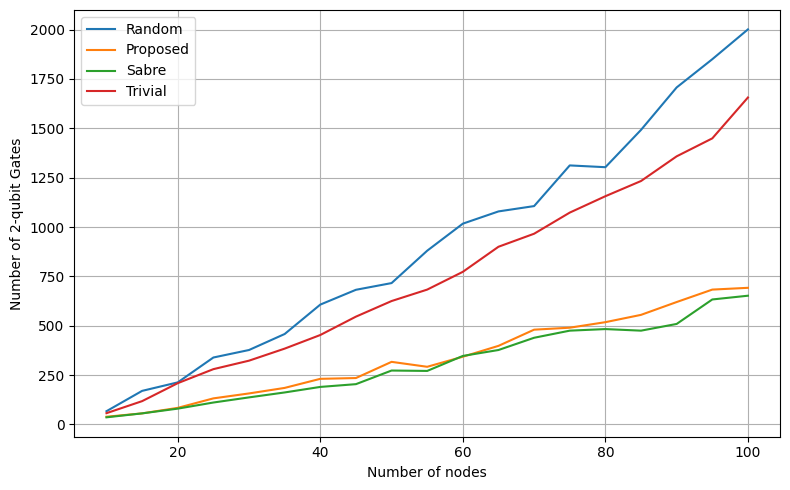

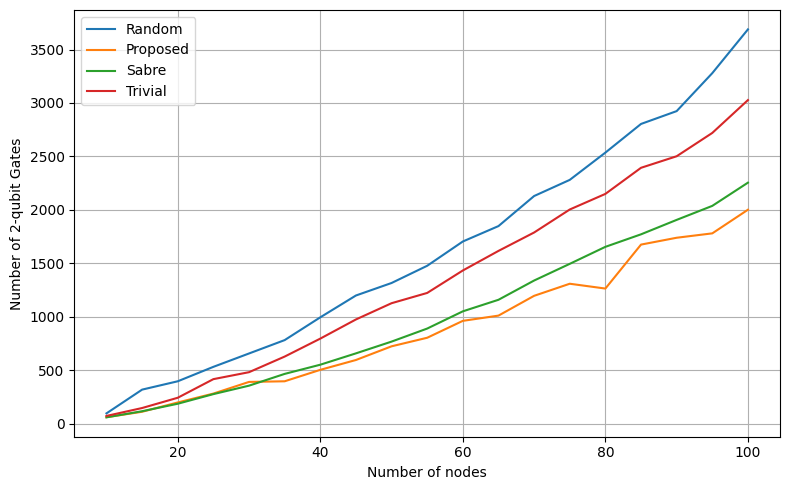

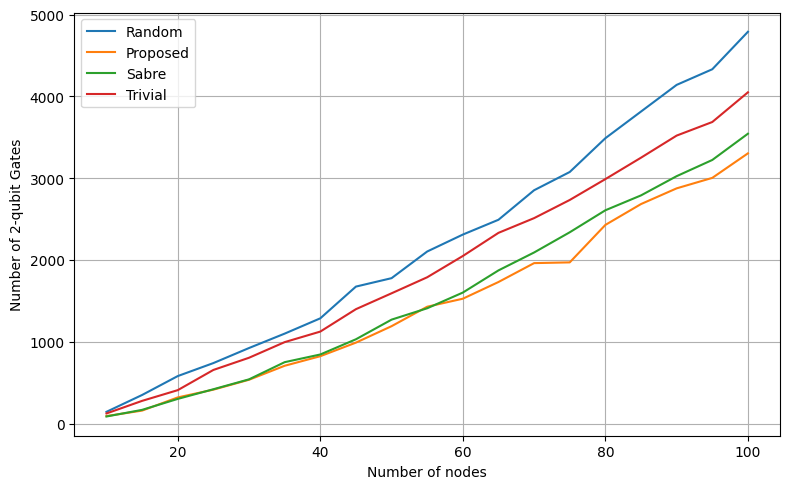

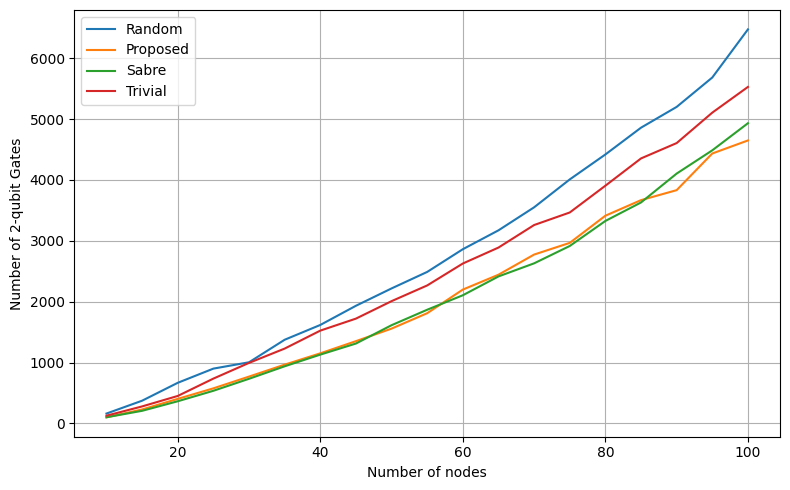

In [134]:
nodes = list(range(10,101,5))
params = list(range(1,5,1))
for param in params:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        plt.plot(nodes, czs_ba[param][s], label=s.capitalize())

    plt.xlabel("Number of nodes")
    plt.ylabel("Number of 2-qubit Gates")
    # plt.title(f"Depth vs Number of Nodes (param = {param})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [463]:
nodes = list(range(10,31,5))
params = list(range(1,5,1))
for param in params:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        plt.plot(nodes, czs_ba[param][s][:5], label=s.capitalize())

    plt.xlabel("Number of nodes")
    plt.ylabel("Number of 2-qubit Gates")
    # plt.title(f"Depth vs Number of Nodes (param = {param})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

NameError: name 'czs_ba' is not defined

<Figure size 800x500 with 0 Axes>

### Depths of Final Circuits for BA Graphs

In [135]:
nodes = list(range(10,101,5))
params = list(range(1,5,1))
depths_ba={}
for param in params:
    depths_ba[param] = return_depths(backend, graph_type='ba', param=param, tree_type='dfs',
                         average_over=1, node_list=nodes,
                         topology='tree', use_custom=True, opt_level=3, reps=1)

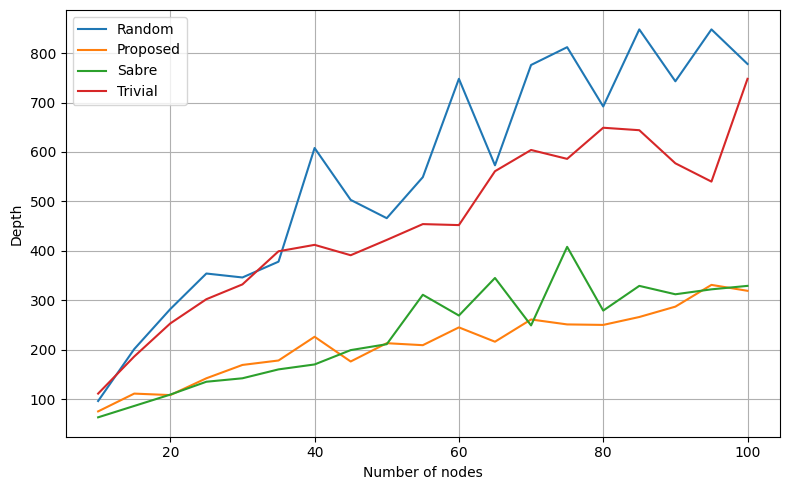

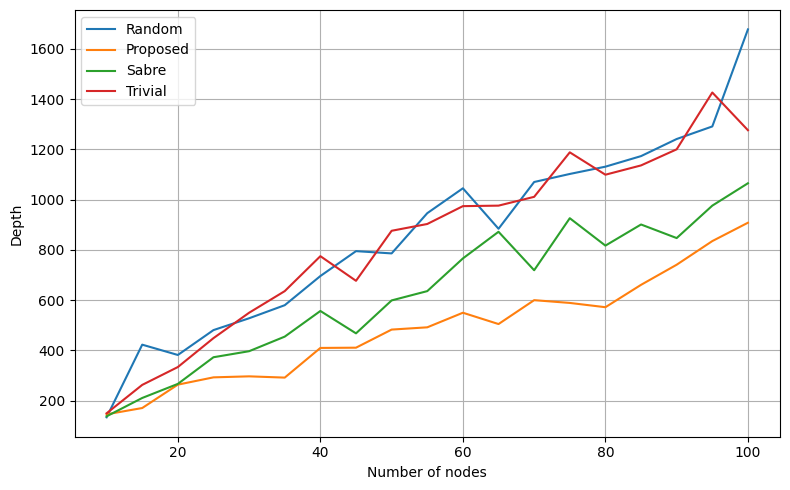

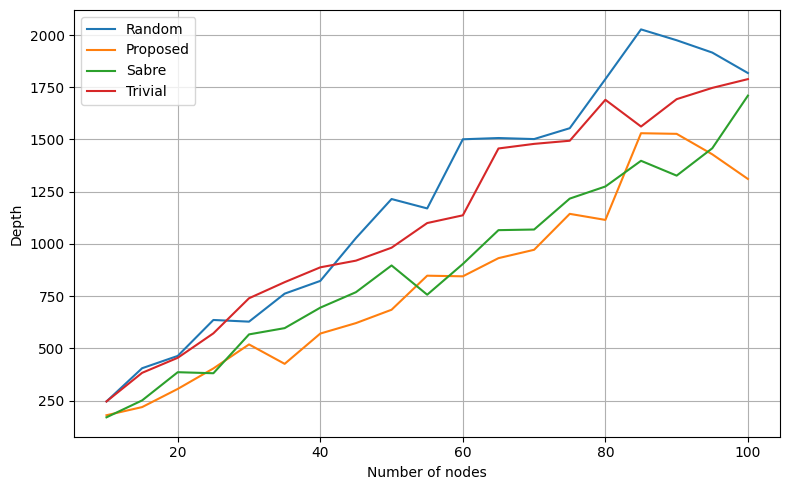

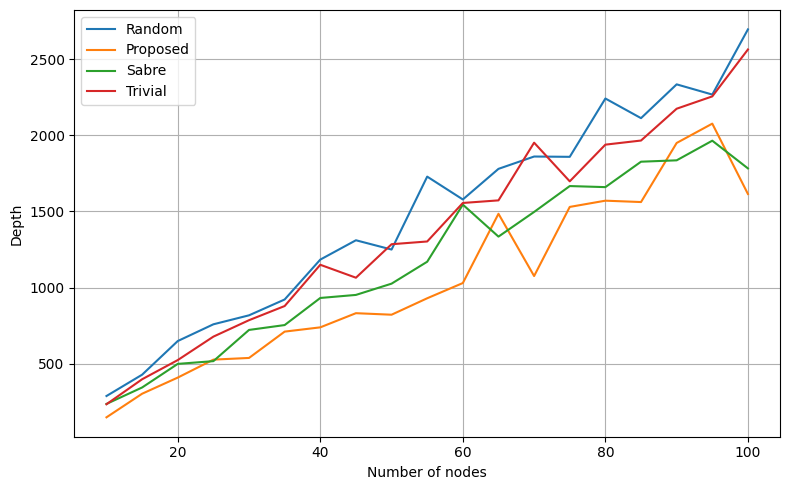

In [136]:
nodes = list(range(10,101,5))
params = list(range(1,5,1))
for param in params:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        plt.plot(nodes, depths_ba[param][s], label=s.capitalize())

    plt.xlabel("Number of nodes")
    plt.ylabel("Depth")
    # plt.title(f"Depth vs Number of Nodes (param = {param})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [79]:
def maxcut_dist(sim, backend, num_nodes, graph_type='reg', param=4, tree_type='dfs', reps=2, opt_level=3, estimator_shots=1000, sampler_shots=1000, root_on_backend=None, want_sabre=True, op_name=None, runs=5):
    if graph_type=='reg':
        graph = nx.random_regular_graph(n=num_nodes, d=param, seed=0)
    else:
        graph = nx.barabasi_albert_graph(n=num_nodes, m=param, seed=0)

    if tree_type=='rand':
        tree = nx.random_spanning_tree(graph, seed=0)
    else:
        tree = dfs_spanning_tree(graph, root=num_nodes//2)

    hamiltonian = get_hamiltonian(graph)
    gen = gen_QAOA_circuit(graph, reps=reps)

    if not root_on_backend:
        root_on_backend = backend.num_qubits//2

    # Distribution with Proposed Initial Mapping
    fied_mapping = initial_layout(tree, backend=backend, how='fiedler', topology='tree_dfs', root_on_backend=root_on_backend)
    prop = custom_qaoa_ansatz(graph, fied_mapping, backend.coupling_map, reps=reps)
    opt_prop = final_optimized_circuit(prop, backend, fied_mapping, opt_level=opt_level)

    # Distribution with no explicit initial mapping set
    opt_gen = final_optimized_circuit(gen_QAOA_circuit(graph, reps=reps), backend, initial_mapping=None, opt_level=opt_level)

    if op_name:
        print('Default=> ', f'{op_name}: ', opt_gen.count_ops().get(f'{op_name}', 0), 'Depth: ',opt_gen.depth())
        # print('SABRE=> ',f'{op_name}: ', opt_sabre.count_ops().get(f'{op_name}', 0),'Depth: ', opt_sabre.depth())
        print('Prop=> ', f'{op_name}: ', opt_prop.count_ops().get(f'{op_name}', 0), 'Depth: ',opt_prop.depth())
    
    results = []
    for _ in tqdm(range(runs), desc=f'Iterating over {runs} runs'):
        prop_dist = QAOA_max_cut(opt_prop, hamiltonian, backend=sim, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)  
        gen_dist = QAOA_max_cut(opt_gen, hamiltonian, backend=sim, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)

        if want_sabre:
            sabre_mapping = sabre_layout(gen, backend)
            opt_sabre = final_optimized_circuit(gen, backend, sabre_mapping, opt_level=opt_level)
            sabre_dist = QAOA_max_cut(opt_sabre, hamiltonian, backend=sim, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)
        else:
            sabre_dist={}
        results.append({'prop':prop_dist, 'sabre':sabre_dist, 'def':gen_dist})

    return results

def execution_ready_circuits(backend, num_nodes, graph_type='reg', param=4, tree_type='dfs', reps=2, opt_level=3, root_on_backend=None, op_name=None):
    if graph_type=='reg':
        graph = nx.random_regular_graph(n=num_nodes, d=param, seed=0)
    else:
        graph = nx.barabasi_albert_graph(n=num_nodes, m=param, seed=0)

    if tree_type=='rand':
        tree = nx.random_spanning_tree(graph, seed=0)
    else:
        tree = dfs_spanning_tree(graph, root=num_nodes//2)

    hamiltonian = get_hamiltonian(graph)
    gen = gen_QAOA_circuit(graph, reps=reps)

    if not root_on_backend:
        root_on_backend = backend.num_qubits//2

    # Distribution with Proposed Initial Mapping
    fied_mapping = initial_layout(tree, backend=backend, how='fiedler', topology='tree_dfs', root_on_backend=root_on_backend)
    prop = custom_qaoa_ansatz(graph, fied_mapping, backend.coupling_map, reps=reps)
    opt_prop = final_optimized_circuit(prop, backend, fied_mapping, opt_level=opt_level)

    # Distribution with no explicit initial mapping set
    opt_gen = final_optimized_circuit(gen_QAOA_circuit(graph, reps=reps), backend, initial_mapping=sabre_layout(gen, backend), opt_level=opt_level)

    if op_name:
        print('Default=> ', f'{op_name}: ', opt_gen.count_ops().get(f'{op_name}', 0), 'Depth: ',opt_gen.depth())
        # print('SABRE=> ',f'{op_name}: ', opt_sabre.count_ops().get(f'{op_name}', 0),'Depth: ', opt_sabre.depth())
        print('Prop=> ', f'{op_name}: ', opt_prop.count_ops().get(f'{op_name}', 0), 'Depth: ',opt_prop.depth())
    return hamiltonian, opt_gen, opt_prop

def return_dists(backend, opt_gen, opt_prop, hamiltonian, reps=1, runs=5, estimator_shots=1000, sampler_shots=1000):
    results = []
    for _ in tqdm(range(runs), desc=f'Iterating over {runs} runs'):
        prop_dist = QAOA_max_cut(opt_prop, hamiltonian, backend=backend, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)  
        gen_dist = QAOA_max_cut(opt_gen, hamiltonian, backend=backend, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)

        sabre_dist={}
        results.append({'prop':prop_dist, 'sabre':sabre_dist, 'def':gen_dist})

    return results

def most_likely_cut(dist: dict):
    keys = list(dist.keys())
    values = list(dist.values())
    most_likely = keys[np.argmax(np.abs(values))]

    return most_likely[::-1]

def expected_size(graph, dist: dict):
    keys = list(dist.keys())
    values = list(dist.values())
    sumValue = 0.0
    
    for key in keys:
        sumValue += dist[key] * evaluate_cut(graph, key[::-1])

    return sumValue

def random_size(graph, dist: dict):
    keys = list(dist.keys())
    numKey = float(len(keys))
    sumValue = 0.0
    
    for key in keys:
        sumValue += evaluate_cut(graph, key[::-1]) / numKey

    return sumValue

In [80]:
def return_ops(backend, graph_type='reg', param=4, tree_type='rand', average_over=5, node_list=list(range(10,101,2)), reps=2, topology='tree_dfs', opt_level=3, op_name='ecr', use_custom=True, stop_after_routing=False):
    swaps = {'SABRE':[], 'Proposed':[], 'Trivial':[], 'Random':[]}
    for n in tqdm(node_list, desc=f'Iterating for number of nodes', leave=False):
        swap_avg = {'sabre':0, 'fied':0, 'triv':0, 'rand':0}

        if graph_type=='reg':
            graph = nx.random_regular_graph(n=n, d=param, seed=0)
        else:
            graph = nx.barabasi_albert_graph(n=n, m=param, seed=0)
        if tree_type=='rand':
            tree = nx.random_spanning_tree(graph, seed=i)
        else:
            tree = dfs_spanning_tree(graph, root=np.random.randint(0,n))
        fiedler_mapping = initial_layout(tree, backend=backend, how='fiedler', topology=topology)
        gen = gen_QAOA_circuit(graph, reps=reps)
        prop=gen
        if use_custom:
            # prop = fiedler_sorted_qaoa(graph, reps=reps)
            prop = custom_qaoa_ansatz(graph, fiedler_mapping, backend.coupling_map, reps=reps)
        
        if stop_after_routing:
            func_with_mapping = custom_routed_circuit
            func_sabre = sabre_routed_circuit
        else:
            func_with_mapping = final_optimized_circuit
            func_sabre = final_optimized_circuit

        swaps['Proposed'].append(func_with_mapping(circuit=prop, backend=backend, initial_mapping=fiedler_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
        
        trivial_mapping = initial_layout(tree, backend=backend, how='trivial')
        swaps['Trivial'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).count_ops().get(op_name, 0))

        random_mapping = initial_layout(tree, backend=backend, how='random')
        swaps['Random'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=random_mapping, opt_level=opt_level).count_ops().get(op_name, 0))

        for i in range(average_over):
            # swap_avg['sabre']+=func_sabre(circuit=gen, backend=backend, opt_level=opt_level).count_ops().get(op_name, 0)
            swap_avg['sabre']+=func_sabre(circuit=gen, backend=backend, initial_mapping=sabre_layout(gen, backend), opt_level=opt_level).count_ops().get(op_name, 0)

        swaps['SABRE'].append(swap_avg['sabre']/(average_over*1.0))

    return swaps

In [81]:
def return_depths(backend, graph_type='reg', param=4, tree_type='rand', average_over=5, node_list=list(range(10,101,2)), reps=2, topology='tree_dfs', opt_level=3, use_custom=True, stop_after_routing=False):
    swaps = {'SABRE':[], 'Proposed':[], 'Trivial':[], 'Random':[]}
    for n in tqdm(node_list, desc=f'Iterating for number of nodes', leave=False):
        swap_avg = {'sabre':0, 'fied':0, 'triv':0, 'rand':0}

        if graph_type=='reg':
            graph = nx.random_regular_graph(n=n, d=param, seed=0)
        else:
            graph = nx.barabasi_albert_graph(n=n, m=param, seed=0)
        if tree_type=='rand':
            tree = nx.random_spanning_tree(graph, seed=i)
        else:
            tree = dfs_spanning_tree(graph, root=np.random.randint(0,n))
        fiedler_mapping = initial_layout(tree, backend=backend, how='fiedler', topology=topology)
        gen = gen_QAOA_circuit(graph, reps=reps)
        prop=gen
        if use_custom:
            # prop = fiedler_sorted_qaoa(graph, reps=reps)
            prop = custom_qaoa_ansatz(graph, fiedler_mapping, backend.coupling_map, reps=reps)
        
        if stop_after_routing:
            func_with_mapping = custom_routed_circuit
            func_sabre = sabre_routed_circuit
        else:
            func_with_mapping = final_optimized_circuit
            func_sabre = final_optimized_circuit

        swaps['Proposed'].append(func_with_mapping(circuit=prop, backend=backend, initial_mapping=fiedler_mapping, opt_level=opt_level).depth())
        
        trivial_mapping = initial_layout(tree, backend=backend, how='trivial')
        swaps['Trivial'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).depth())

        random_mapping = initial_layout(tree, backend=backend, how='random')
        swaps['Random'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=random_mapping, opt_level=opt_level).depth())

        for i in range(average_over):
            swap_avg['sabre']+=func_sabre(circuit=gen, backend=backend, opt_level=opt_level).depth()

        swaps['SABRE'].append(swap_avg['sabre']/(average_over*1.0))

    return swaps

In [83]:
from qiskit_ibm_runtime.fake_provider import FakeTorino, FakeFez, FakeBrisbane
backend = FakeFez()

In [84]:
import matplotlib.pyplot as plt

nodes = list(range(6, 101, 2))
params = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, tree_type='dfs',
                         average_over=10, node_list=nodes,
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

Iterating for number of nodes:   0%|          | 0/48 [00:00<?, ?it/s]C:\Users\devra\AppData\Local\Temp\ipykernel_18868\69950173.py:209: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  adj_matrix = nx.adjacency_matrix(graph, nodelist=range(graph.number_of_nodes())).todense()


TypeError: sabre_routed_circuit() got an unexpected keyword argument 'initial_mapping'

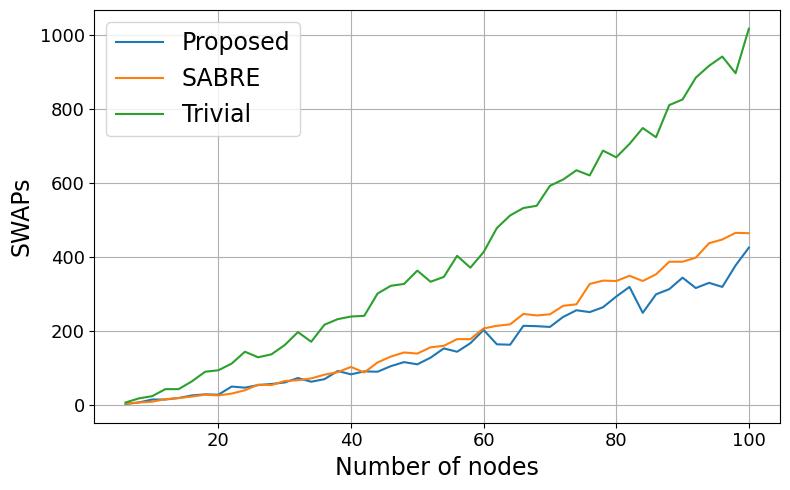

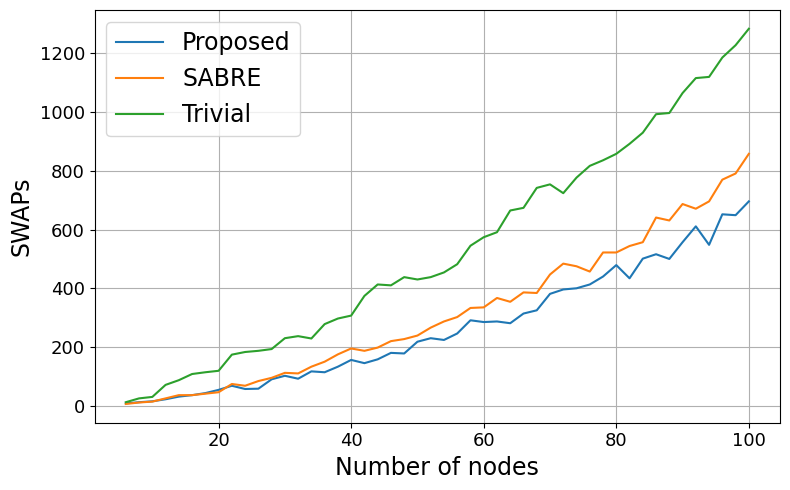

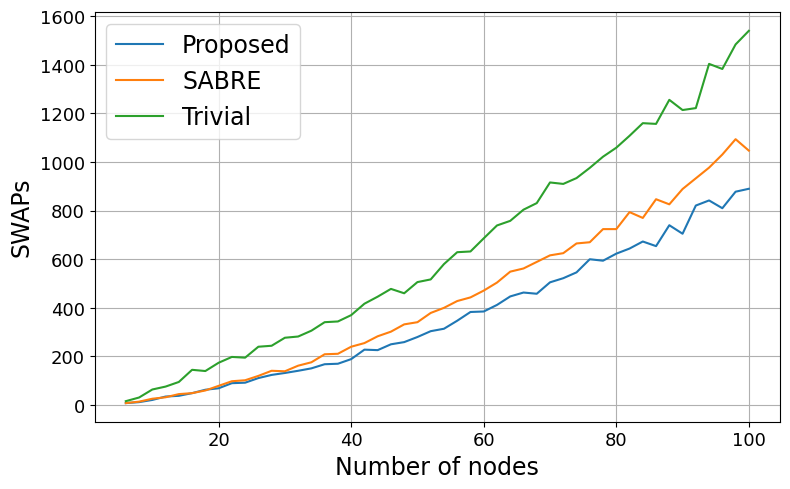

In [ ]:
nodes = list(range(6, 101, 2))
params = list(range(3,6,1))
for param in params:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        if s!='Random':
            plt.plot(nodes, swaps_reg[param][s], label=s)

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title(f"SWAPs vs Number of Nodes\nFor {param}-regular graphs")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend( fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()